# Kryptonite-3.0: model experiments (section 1B)

Compares model families on Kryptonite-20/30/40 under one protocol, picks one pipeline per dataset, scores it once on a locked test set, and writes the hidden-set predictions. Numbers go to `exp_results/`, figures to `exp_figures/`.

**Run.** From this folder: *Restart & Run All*. `Datasets/`, `hiddenlabels/` and `check_submission.py` are at the repository root, above this folder (any depth up to three levels). Results are saved as they finish, so an interrupted run resumes when started again, and a stored result is used only if the machine, library versions, seed and grids are the same (otherwise the notebook stops and says what differs; delete `exp_results/` and `exp_figures/` to start over). `KRYP_QUICK=1` is a dry run on tiny data (never report its numbers). Machine, library versions, seed, grids and splits are recorded in `exp_results/`.

**Protocol.**
1. A stratified 20 % of the labelled rows is a **locked test set**, not read before section 10.
2. The other 80 % (dev) is split into 5 stratified folds. Every comparison and hyper-parameter choice uses these folds; feature selection and early stopping happen inside the training folds.
3. Models are compared by paired fold differences with Nadeau–Bengio intervals. No fixed threshold for "better".
4. The best pipeline by CV mean is refitted on all dev rows and scored **once** on the locked set.

| Section | Question | Figure |
|---|---|---|
| 1 | The paper's baseline under this protocol | |
| 2 | Logistic regression: L1 vs L2, polynomial degree 1–4 | `fig_lr_degree` |
| 3 | Polynomial logistic regression of degree ≥ n (kernel) | `fig_kernel_degree` |
| 4–5 | Trees, boosting, K-means; MLPs from scratch | `fig_generic` |
| 6–7 | A bit selector in front of a forest, and in front of a polynomial LR on all monomials of the selected bits | `fig_selected_bits` |
| 8 | Paired comparison, choice of final pipeline | `fig_cv_overview` |
| 9 | Learning curves | `fig_learning_curves` |
| 10 | Locked test, hidden predictions | `fig_paper_figure2_reproduction` |

**Verified vs hypothesised.** Verified by the checks below: the inputs are $\pm 1$ bits plus noise of sd about 0.1, so `sign(X)` recovers the bits. Hypotheses until a result says otherwise: that the label depends on about 10 of the n bits, and that the remaining few per cent of errors are label noise (the check after section 7 neither confirms nor rules this out).

## 0. Setup, protocol and tests

In [1]:
import csv, hashlib, itertools, json, os, time, warnings
from functools import lru_cache
from math import comb

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeClassifier

# ---- settings you may change True = dry run (see below); set with the KRYP_QUICK environment
# variable
QUICK = os.environ.get("KRYP_QUICK", "0") == "1"
# repository root: the first of ., .., ../.., ../../.. that contains Datasets/
ROOT = next((p for p in (".", "..", "../..", "../../..") if os.path.isdir(f"{p}/Datasets")), ".")
DATA = os.environ.get("KRYP_DATA", f"{ROOT}/Datasets")  # folder with the .npy files
# predictions for grading go to the top-level hiddenlabels/ folder
HIDDEN = f"{ROOT}/hiddenlabels"
WRITE_PREDICTIONS = True  # section 10 writes hiddenlabels/y_predicted_{20,30,40}.npy
# section 5: one 4 x 512 MLP (KryptoNet's shape), trained from scratch on fold 0 only because it is
# slow
RUN_KRYPTONET_SIZED = True

# ---- derived settings
NS = (20, 30, 40)
# one seed: it fixes the locked split, the folds and every model's random_state
SEED = 0
K = 5  # CV folds
ROWS = None  # None = all labelled rows
OUT, FIG = "exp_results", "exp_figures"

# Search grids. MAX_DEG is the memory rule for explicit polynomial features: at most ~6,200 columns
# on all bits (degree 4 for n=20 is 6,195 columns, degree 3 for n=30 is 4,525, degree 2 for n=40 is
# 820).
G = dict(
    C_L2=[1e-3, 1e-2, 1e-1, 1],
    C_L1=[3e-3, 1e-2, 3e-2, 1e-1],
    MAX_DEG={20: 4, 30: 3, 40: 2},
    DT_DEPTH=[2, 4, 6, 8, 12, None],
    DT_LEAF=[1, 10],
    RF_TREES=200,
    RF_MAXF=["sqrt", 0.5, 1.0],
    RF_LEAF=[1, 5],
    HGB_DEPTH=[3, 6, None],
    KM_K=[8, 32, 128],
    MLP_H=[[128, 128]],
    # polynomial-kernel LR (section 3): degree 10 as in the paper, n and 2n
    KP_DEGS={20: [10, 20, 40], 30: [10, 30, 60], 40: [10, 40, 80]},
    KP_C=0.85,
    MLP_ALPHA=[1e-2],
    MLP_MAXITER=400,
    # 4 x 512 MLP: epoch cap that bounds its run time (it may stop before converging)
    KN_MAXITER=60,
    KN_PATIENCE=15,
    MLP_PATIENCE=50,  # long patience: the net may sit on a plateau before it learns anything
    SEL_RF_MAXF=["sqrt", 1.0],  # second-stage forest on the selected bits
    SEL_RF_LEAF=[1, 5],
    LC_SIZES=[250, 500, 1000, 2000, 4000],  # learning curves (the full fold-train set is added)
    LC_FOLDS=(0, 1, 2),
    LC_TOP=3,
    NULL_REPS=20,  # shuffled-label repetitions of the selector per n
)

# ---- dry run (KRYP_QUICK=1) A tiny version of this notebook, only to check that the code runs from
# start to finish: 3 folds, 3,000 rows, smaller grids, its own result folders, no predictions
# written. Its numbers mean nothing and are never reported. Everything above is the real setup.
if QUICK:
    K, ROWS, OUT, FIG, WRITE_PREDICTIONS = 3, 3000, "exp_results_quick", "exp_figures_quick", False
    G.update(
        C_L2=[1e-2, 1e-1],
        C_L1=[1e-2, 1e-1],
        MAX_DEG={20: 2, 30: 2, 40: 2},
        DT_DEPTH=[4, None],
        DT_LEAF=[1, 10],
        RF_TREES=30,
        RF_MAXF=["sqrt", 1.0],
        HGB_DEPTH=[3, None],
        KM_K=[4, 16],
        MLP_H=[[64, 64]],
        KP_DEGS={20: [10, 20], 30: [10, 30], 40: [10, 40]},
        MLP_MAXITER=40,
        KN_MAXITER=40,
        KN_PATIENCE=10,
        MLP_PATIENCE=10,
        LC_SIZES=[100, 250, 500],
        LC_FOLDS=(0, 1),
        LC_TOP=2,
        NULL_REPS=3,
    )

if not os.path.isfile(f"{DATA}/kryptonite-20-X.npy"):
    raise FileNotFoundError(
        f"cannot find {DATA}/kryptonite-20-X.npy: run the notebook from its own folder inside the"
        " repository (Datasets/ is looked for in this folder and up to three levels above it), or"
        " set KRYP_DATA to the data folder"
    )
os.makedirs(OUT, exist_ok=True)
os.makedirs(FIG, exist_ok=True)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", message=".*encountered in matmul")
print(
    "QUICK" if QUICK else "FULL", f"run; {K}-fold CV on 80% dev, 20% locked test; results ->", OUT
)

FULL run; 5-fold CV on 80% dev, 20% locked test; results -> exp_results


In [2]:
# ---- figure style Figures are drawn at their final size (ICML text width 6.75 in, one column 3.25
# in) with 9-10 pt text, so they are not rescaled in the report.
plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 10,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "lines.linewidth": 2,
    "lines.markersize": 5,
    "legend.frameon": False,
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
})
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, INK, GRAY, ROSE = (
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#52514e",
    "#9a9892",
    "#b0446c",
)
# colour follows the entity; every line also has its own marker so nothing depends on colour alone
COL = dict(
    lr_l2=BLUE,
    lr_l1=ORANGE,
    kpoly=VIOLET,
    lrfull=ROSE,
    dtree=YELLOW,
    rf=AQUA,
    hgb=GREEN,
    mlp=MAGENTA,
    kmeans_major=GRAY,
    kmeans_onehot=INK,
    paper=GRAY,
)
MK = dict(
    lr_l2="o",
    lr_l1="s",
    kpoly="D",
    lrfull="*",
    dtree="^",
    rf="D",
    hgb="v",
    mlp="P",
    kmeans_major="x",
    kmeans_onehot="+",
    paper="x",
)
NAME = dict(
    lr_l2="LR, L2",
    lr_l1="LR, L1",
    kpoly="LR, polynomial kernel",
    lrfull="LR on all monomials",
    dtree="decision tree",
    rf="random forest",
    hgb="gradient boosting",
    mlp="MLP",
    kmeans_major="K-means, cluster majority",
    kmeans_onehot="K-means, one-hot + LR",
    paper="paper baseline (quadratic LR)",
)
CONDNAME = {"all": "all bits", "sel": "selected bits"}
N_COL = {20: BLUE, 30: ORANGE, 40: AQUA}


def savefig(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(f"{FIG}/{name}.{ext}")
    plt.show()
    print(f"saved {FIG}/{name}.pdf")


def md_table(header, rows):
    out = ["| " + " | ".join(header) + " |", "|" + "|".join(["---"] * len(header)) + "|"]
    out += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    return "\n".join(out)

In [3]:
# ---- data and the validation protocol
_DATA = {}


def load(n):
    # X (noisy), B (the bits sign(X), +-1) and y. The noise (sd 0.1) is far too small to flip a
    # sign, so sign(X) recovers the bits.
    if n not in _DATA:
        X = np.load(f"{DATA}/kryptonite-{n}-X.npy")
        y = np.load(f"{DATA}/kryptonite-{n}-y.npy").astype(np.int64)
        if ROWS:
            keep, _ = train_test_split(
                np.arange(len(y)), train_size=ROWS, stratify=y, random_state=0
            )
            X, y = X[keep], y[keep]
        _DATA[n] = (X, np.where(X > 0, 1.0, -1.0).astype(np.float32), y)
    return _DATA[n]


DEV, FOLDS, _LOCKED_IDX = {}, {}, {}
for n in NS:
    X, B, y = load(n)
    idx = np.arange(len(y))
    dev, locked = train_test_split(idx, test_size=0.2, random_state=SEED, stratify=y)
    DEV[n], _LOCKED_IDX[n] = dev, locked  # _LOCKED_IDX is read by section 10 only
    FOLDS[n] = [
        (dev[a], dev[b])
        for a, b in StratifiedKFold(K, shuffle=True, random_state=SEED).split(dev, y[dev])
    ]
FOLD_TRAIN = {n: len(FOLDS[n][0][0]) for n in NS}

# ---- tests of the protocol
for n in NS:
    X, B, y = load(n)
    assert set(np.unique(y)) <= {0, 1}, "labels must be 0/1"
    assert np.mean(np.abs(X - B) < 0.5) > 0.9999, "rounding to bits would lose information"
    assert not (set(DEV[n]) & set(_LOCKED_IDX[n])) and len(DEV[n]) + len(_LOCKED_IDX[n]) == len(
        y
    ), "dev and locked test must partition the rows"
    va_all = np.concatenate([va for _, va in FOLDS[n]])
    assert sorted(va_all) == sorted(DEV[n]), "validation folds must partition dev exactly"
    for tr, va in FOLDS[n]:
        assert (
            not (set(tr) & set(va))
            and not (set(tr) & set(_LOCKED_IDX[n]))
            and not (set(va) & set(_LOCKED_IDX[n]))
        ), "overlap between train, validation, locked test"
        assert (
            abs(y[tr].mean() - y.mean()) < 0.02 and abs(y[va].mean() - y.mean()) < 0.03
        ), "stratification failed"
    print(
        f"n={n}: {len(y)} labelled rows = {len(DEV[n])} dev ({K} folds, {FOLD_TRAIN[n]} train /"
        f" {len(FOLDS[n][0][1])} validation rows each) + {len(_LOCKED_IDX[n])} locked;"
        f" {np.mean(y):.3f} positive; noise sd {np.std(X - B):.3f}"
    )
assert PolynomialFeatures(3, interaction_only=True, include_bias=False).fit_transform(
    np.ones((2, 20))
).shape[1] == 20 + comb(20, 2) + comb(20, 3)

n=20: 12000 labelled rows = 9600 dev (5 folds, 7680 train / 1920 validation rows each) + 2400 locked; 0.496 positive; noise sd 0.100
n=30: 20000 labelled rows = 16000 dev (5 folds, 12800 train / 3200 validation rows each) + 4000 locked; 0.499 positive; noise sd 0.100
n=40: 32000 labelled rows = 25600 dev (5 folds, 20480 train / 5120 validation rows each) + 6400 locked; 0.498 positive; noise sd 0.100


In [4]:
# ---- reproducibility record: machine, versions, seeds, splits Written to OUT/environment.json
# (first session), OUT/sessions.jsonl (one line per session, so interruptions are visible) and
# OUT/splits.npz. A stored result is only reused by a session whose machine, library versions,
# settings and grids match the session that began the results: a results folder copied from another
# machine stops here instead of silently mixing numbers (set KRYP_ALLOW_FOREIGN_CACHE=1 to
# override).
import datetime, platform, subprocess, sys
from importlib import metadata as _md


def _cpu_model():
    try:
        for line in open("/proc/cpuinfo"):
            if line.lower().startswith("model name"):
                return line.split(":", 1)[1].strip()
    except OSError:
        pass
    try:
        out = subprocess.run(
            ["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True, text=True, timeout=5
        ).stdout.strip()
    except Exception:
        out = ""
    return out or platform.processor() or "unknown"


def _ram_gb():
    try:
        for line in open("/proc/meminfo"):
            if line.startswith("MemTotal"):
                return round(int(line.split()[1]) / 2**20, 1)
    except OSError:
        pass
    try:
        return round(os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 2**30, 1)
    except (ValueError, OSError, AttributeError):
        pass
    # Windows: GlobalMemoryStatusEx (MEMORYSTATUSEX is 64 bytes)
    try:
        import ctypes

        class _MS(ctypes.Structure):
            _fields_ = [("len", ctypes.c_uint32), ("load", ctypes.c_uint32)] + [
                (f"f{i}", ctypes.c_uint64) for i in range(7)
            ]

        ms = _MS()
        ms.len = ctypes.sizeof(ms)
        if ctypes.windll.kernel32.GlobalMemoryStatusEx(ctypes.byref(ms)):
            return round(ms.f0 / 2**30, 1)
    except Exception:
        pass
    # Windows fallback: ask PowerShell
    try:
        out = subprocess.run(
            [
                "powershell",
                "-NoProfile",
                "-Command",
                "(Get-CimInstance Win32_ComputerSystem).TotalPhysicalMemory",
            ],
            capture_output=True,
            text=True,
            timeout=15,
        ).stdout.strip()
        return round(int(out) / 2**30, 1)
    except Exception:
        return None


def _pkg(name):
    try:
        return _md.version(name)
    except _md.PackageNotFoundError:
        return None


def _git():
    try:

        def g(*a):
            return subprocess.run(
                ["git", *a], capture_output=True, text=True, timeout=10
            ).stdout.strip()

        return dict(
            commit=g("rev-parse", "HEAD") or None,
            uncommitted_changes=bool(g("status", "--porcelain")),
        )
    except Exception:
        return dict(commit=None, uncommitted_changes=None)


try:
    from threadpoolctl import threadpool_info

    _tp = [
        dict(api=t.get("user_api"), library=t.get("internal_api"), threads=t.get("num_threads"))
        for t in threadpool_info()
    ]
except Exception:
    _tp = None

ENV = dict(
    started_utc=datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
    python=sys.version.split()[0],
    python_executable=sys.executable,
    platform=platform.platform(),
    cpu=_cpu_model(),
    logical_cpus=os.cpu_count(),
    ram_gb=_ram_gb(),
    packages={
        p: _pkg(p)
        for p in (
            "numpy",
            "scipy",
            "scikit-learn",
            "matplotlib",
            "ipykernel",
            "nbconvert",
            "nbclient",
            "threadpoolctl",
        )
    },
    blas_and_openmp_threads=_tp,
    thread_env={
        k: os.environ.get(k) for k in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS")
    },
    git=_git(),
    quick=QUICK,
    seed=SEED,
    cv_folds=K,
    n_values=list(NS),
    data_dir=DATA,
)
GRID_HASH = hashlib.sha1(json.dumps(G, sort_keys=True, default=str).encode()).hexdigest()[:12]
FINGERPRINT = dict(
    cpu=ENV["cpu"],
    logical_cpus=ENV["logical_cpus"],
    python=".".join(ENV["python"].split(".")[:2]),
    numpy=ENV["packages"]["numpy"],
    scipy=ENV["packages"]["scipy"],
    scikit_learn=ENV["packages"]["scikit-learn"],
    quick=QUICK,
    seed=SEED,
    cv_folds=K,
    grid=GRID_HASH,
)

In [5]:
_env_file = f"{OUT}/environment.json"
if os.path.exists(_env_file):
    _was = json.load(open(_env_file))["fingerprint"]
    _diff = {k: dict(stored=_was.get(k), now=v) for k, v in FINGERPRINT.items() if _was.get(k) != v}
    if _diff and os.environ.get("KRYP_ALLOW_FOREIGN_CACHE") != "1":
        raise RuntimeError(
            f"{OUT}/ was started by a different setup, so its stored results must not be mixed with"
            f" this run: {json.dumps(_diff, indent=1)}\nDelete {OUT}/ and {FIG}/ to start a fresh"
            " run on this machine (or set KRYP_ALLOW_FOREIGN_CACHE=1 if you know what you are"
            " doing)."
        )
elif os.path.exists(f"{OUT}/cv_results.jsonl"):
    raise RuntimeError(
        f"{OUT}/ holds results but no environment.json, so their origin is unknown. Delete {OUT}/"
        f" and {FIG}/ to start a fresh run."
    )
else:
    json.dump(dict(first_session=ENV, fingerprint=FINGERPRINT), open(_env_file, "w"), indent=1)
with open(f"{OUT}/sessions.jsonl", "a") as f:
    f.write(json.dumps(dict(event="start", **ENV)) + "\n")

In [6]:
# data splits: row indices into the .npy files. Written once; every later session must reproduce
# them exactly.
_splits = {}
for n in NS:
    _splits[f"dev_{n}"], _splits[f"locked_{n}"] = DEV[n], _LOCKED_IDX[n]
    for i, (tr, va) in enumerate(FOLDS[n]):
        _splits[f"fold{i}_validation_{n}"] = va
_splits_file = f"{OUT}/splits.npz"
if os.path.exists(_splits_file):
    _was = np.load(_splits_file)
    assert set(_was.files) == set(_splits) and all(
        np.array_equal(_was[k], _splits[k]) for k in _splits
    ), "the data splits differ from the stored ones: data, seed or library changed"
else:
    np.savez_compressed(_splits_file, **_splits)

print(
    f"machine : {ENV['cpu']}, {ENV['logical_cpus']} logical CPUs, {ENV['ram_gb']} GB RAM,"
    f" {ENV['platform']}"
)
print(
    "software:",
    f"python {ENV['python']}",
    ", ".join(
        f"{k} {v}"
        for k, v in ENV["packages"].items()
        if k in ("numpy", "scipy", "scikit-learn", "matplotlib")
    ),
)
print(
    f"seed {SEED}, {K}-fold CV, grid hash {GRID_HASH}; locked-split fingerprints:",
    {n: hashlib.sha1(np.sort(_LOCKED_IDX[n]).tobytes()).hexdigest()[:8] for n in NS},
)

machine : Intel64 Family 6 Model 183 Stepping 1, GenuineIntel, 32 logical CPUs, 15.7 GB RAM, Windows-11-10.0.26200-SP0
software: python 3.12.3 numpy 2.5.4, scipy 1.18.1, scikit-learn 1.9.1, matplotlib 3.11.2
seed 0, 5-fold CV, grid hash 83f39b867b50; locked-split fingerprints: {20: '6a0fc929', 30: '5dbd2c9d', 40: '3aa88d44'}


In [7]:
# ---- result store (resumable, one JSON line per result)
class Store:
    def __init__(self, name):
        self.path, self.rows = f"{OUT}/{name}.jsonl", {}
        if os.path.exists(self.path):
            for line in open(self.path):
                r = json.loads(line)
                self.rows[r["key"]] = r

    def where(self, **kw):
        return [r for r in self.rows.values() if all(r.get(k) == v for k, v in kw.items())]


CV, LC, NUL, FIN = (Store(nm) for nm in ("cv_results", "learning_curves", "selector_null", "final"))


def run(store, key, fn, quiet=False, **meta):
    # run fn() unless this key is already stored; fn returns a dict (folds/mean/sd/secs/...); meta
    # labels the row
    if key in store.rows:
        return store.rows[key]
    row = fn()
    row.update(key=key, **meta)
    store.rows[key] = row
    with open(store.path, "a") as f:
        f.write(json.dumps(row) + "\n")
    if not quiet:
        print(f"{key:<62} {row['mean']:.3f} ± {row['sd']:.3f}  ({row.get('secs', 0)}s)")
    return row


def acc(m, X, y):
    return float((m.predict(X) == y).mean())


def cv_eval(make, n, fam="", size=None, folds=None, post=None, shuffle_labels=False):
    # K-fold CV on dev: fit make() on the training folds, score on the held-out fold. size: use only
    # that many training rows (a fixed random subset of each fold-train set). Returns per-fold
    # accuracies, so models can be compared fold by fold.
    X, B, y = load(n)
    M = X if fam == "paper" else B
    t0, accs, trs, posts = time.time(), [], [], []
    for f, (tr, va) in enumerate(FOLDS[n]):
        if folds is not None and f not in folds:
            continue
        if size is not None and size < len(tr):
            tr = tr[np.random.default_rng(SEED + f).permutation(len(tr))[:size]]
        ytr = np.random.default_rng(1000 + f).permutation(y[tr]) if shuffle_labels else y[tr]
        est = make().fit(M[tr], ytr)
        accs.append(acc(est, M[va], y[va]))
        trs.append(acc(est, M[tr], ytr))
        if post:
            posts.append(post(est))
    return dict(
        folds=[round(a, 5) for a in accs],
        mean=float(np.mean(accs)),
        sd=float(np.std(accs, ddof=1)) if len(accs) > 1 else 0.0,
        train=float(np.mean(trs)),
        secs=round(time.time() - t0, 1),
        post=posts,
    )

In [8]:
# ---- models
@lru_cache(None)
def paper_kernel_table(n, degree):
    # phi(x).phi(x') for PolynomialFeatures(degree) on +-1 bits, as a function of the number m of
    # agreeing bits, normalised to k(x, x) = 1. This is the mock paper's own kernel (its Figure 1
    # code), computed here in exact integer arithmetic so that degrees above 10 stay accurate.
    from fractions import Fraction

    tab = [0] * (n + 1)
    for s in range(min(degree, n) + 1):
        w = comb(n + (degree - s) // 2, n)
        for m in range(n + 1):
            tab[m] += w * sum(
                comb(m, a) * comb(n - m, s - a) * (-1) ** (s - a) for a in range(s + 1)
            )
    return np.array([float(Fraction(t, tab[n])) for t in tab])


class KernelPolyLR:
    # Logistic regression with the mock paper's polynomial kernel (that of PolynomialFeatures(d) on
    # the bits), trained in the dual, so the up to 2^n monomial features are never built: only the N
    # x N Gram matrix of the training rows. The penalty is a'Ka / (2C), i.e. sklearn's L2 penalty on
    # the implicit weights, so C means what it means in LogisticRegression. Same model as the
    # paper's Figure 1, with a different optimiser (L-BFGS instead of Newton) so that degrees above
    # 10 can be run.
    def __init__(self, deg, C, maxiter=500):
        self.deg, self.C, self.maxiter = deg, C, maxiter

    def _gram(self, A, B):
        n = A.shape[1]
        tab = paper_kernel_table(n, self.deg)
        A = np.asarray(A, np.float32)
        B = np.asarray(B, np.float32)
        K = np.empty((len(A), len(B)))
        # row blocks: no large temporaries
        for i in range(0, len(A), 1000):
            K[i : i + 1000] = tab[np.rint((n + A[i : i + 1000] @ B.T) / 2).astype(np.int64)]
        return K

    def fit(self, B, y):
        from scipy.optimize import minimize
        from scipy.special import expit

        N = len(y)
        K = self._gram(B, B)
        s = 2.0 * y - 1
        C = self.C

        def fg(p):
            # g: derivative of the logistic loss in f
            a, b = p[:N], p[N]
            Ka = K @ a
            m = -s * (Ka + b)
            g = -s * expit(m)
            return np.logaddexp(0, m).sum() + 0.5 / C * (a @ Ka), np.append(K @ g + Ka / C, g.sum())

        r = minimize(
            fg,
            np.zeros(N + 1),
            jac=True,
            method="L-BFGS-B",
            options=dict(maxiter=self.maxiter, maxcor=20),
        )
        self.a_, self.b_, self.B_, self.iters_ = (
            r.x[:N],
            r.x[N],
            np.asarray(B, np.float32),
            int(r.nit),
        )
        self.f_train_ = K @ self.a_ + self.b_
        return self

    def decision_function(self, B):
        B = np.asarray(B, np.float32)
        # scoring the training rows: reuse, do not rebuild the Gram matrix
        if B.shape == self.B_.shape and np.array_equal(B, self.B_):
            return self.f_train_
        return self._gram(B, self.B_) @ self.a_ + self.b_

    def predict(self, B):
        return (self.decision_function(B) > 0).astype(np.int64)


class FullPolyLR:
    # logistic regression on ALL 2^k - 1 products of distinct bits of its k input columns (a
    # polynomial of degree k, so it can represent any function of those k bits). Only meant for a
    # small k: it is used behind the bit selector, which keeps k <= 14.
    def __init__(self, pen, C):
        self.pen, self.C = pen, C

    def fit(self, B, y):
        self.pf_ = PolynomialFeatures(B.shape[1], interaction_only=True, include_bias=False).fit(B)
        self.lr_ = lr_clf(self.pen, self.C).fit(self.pf_.transform(B), y)
        return self

    def predict(self, B):
        return self.lr_.predict(self.pf_.transform(B))

In [9]:
class PaperBaseline:
    # the mock paper's model: PolynomialFeatures(2) on the raw inputs, logistic regression, C = 0.85
    def fit(self, X, y):
        self.pf_ = PolynomialFeatures(2)
        self.m_ = LogisticRegression(max_iter=100, solver="sag", C=0.85, random_state=SEED).fit(
            self.pf_.fit_transform(X), y
        )
        return self

    def predict(self, X):
        return self.m_.predict(self.pf_.transform(X))


class KMeansMajority:
    # K-means on the bits (fitted on the training rows only); each cluster predicts its training
    # majority label
    def __init__(self, k):
        self.k = k

    def fit(self, B, y):
        self.km_ = KMeans(self.k, n_init=3, max_iter=100, random_state=SEED).fit(B)
        lab = self.km_.labels_
        cnt = np.bincount(lab, minlength=self.k)
        pos = np.bincount(lab, weights=y, minlength=self.k)
        self.vote_ = (np.where(cnt > 0, pos / np.maximum(cnt, 1), y.mean()) > 0.5).astype(np.int64)
        return self

    def predict(self, B):
        return self.vote_[self.km_.predict(B)]


class KMeansOneHot:
    # cluster assignment (one-hot) as the only features of a logistic regression
    def __init__(self, k):
        self.k = k

    def fit(self, B, y):
        self.km_ = KMeans(self.k, n_init=3, max_iter=100, random_state=SEED).fit(B)
        self.lr_ = LogisticRegression(C=1.0, max_iter=300).fit(
            np.eye(self.k, dtype=np.float32)[self.km_.labels_], y
        )
        return self

    def predict(self, B):
        return self.lr_.predict(np.eye(self.k, dtype=np.float32)[self.km_.predict(B)])


import sklearn

# penalty= is deprecated since 1.8 in favour of l1_ratio=
NEW_SKLEARN = tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 8)


def lr_clf(pen, C):
    if pen == "l2":
        return LogisticRegression(C=C, max_iter=300)
    if NEW_SKLEARN:
        return LogisticRegression(
            C=C, l1_ratio=1, solver="liblinear", max_iter=100, random_state=SEED
        )
    return LogisticRegression(
        C=C, penalty="l1", solver="liblinear", max_iter=100, random_state=SEED
    )


def make_estimator(family, p, cond="all"):
    # one place that knows how to build every model. p: JSON-friendly hyper-parameters. cond: 'all'
    # bits, or 'sel' = the bit selector of section 6 runs INSIDE fit(), on whatever rows fit() is
    # given.
    if family in ("lr_l1", "lr_l2"):
        est = Pipeline([
            ("poly", PolynomialFeatures(p["deg"], interaction_only=True, include_bias=False)),
            ("lr", lr_clf(family[-2:], p["C"])),
        ])
    elif family == "dtree":
        est = DecisionTreeClassifier(
            max_depth=p["max_depth"], min_samples_leaf=p["msl"], random_state=SEED
        )
    elif family == "rf":
        est = RandomForestClassifier(
            G["RF_TREES"],
            max_features=p["max_features"],
            min_samples_leaf=p["msl"],
            n_jobs=-1,
            random_state=SEED,
        )
    elif family == "hgb":
        est = HistGradientBoostingClassifier(
            max_depth=p["max_depth"],
            max_iter=300,
            learning_rate=0.1,
            early_stopping=True,
            random_state=SEED,
        )
    elif family == "mlp":
        est = MLPClassifier(
            tuple(p["h"]),
            alpha=p["alpha"],
            early_stopping=True,
            n_iter_no_change=G["MLP_PATIENCE"],
            max_iter=G["MLP_MAXITER"],
            random_state=SEED,
        )
    elif family == "kmeans_major":
        est = KMeansMajority(p["k"])
    elif family == "kmeans_onehot":
        est = KMeansOneHot(p["k"])
    elif family == "lrfull":
        est = FullPolyLR(p["pen"], p["C"])
    elif family == "kpoly":
        est = KernelPolyLR(p["deg"], p["C"])
    elif family == "paper":
        est = PaperBaseline()
    else:
        raise ValueError(family)
    # BitModel (the bit selector) is defined in section 6
    return BitModel(est) if cond == "sel" else est


def cv_config(n, exp, family, cond, sub, p, post=None, **kw):
    key = f"{exp}|{n}|{family}|{cond}|{sub}|{json.dumps(p, sort_keys=True)}"
    return run(
        CV,
        key,
        lambda: cv_eval(lambda: make_estimator(family, p, cond), n, fam=family, post=post, **kw),
        exp=exp,
        n=n,
        family=family,
        cond=cond,
        sub=sub,
        params=p,
    )

In [10]:
# ---- comparing candidates
def groups(n):
    # one entry per (family, condition, sub-model); 'best' is its CV-best hyper-parameter setting
    d = {}
    for r in CV.rows.values():
        if r["n"] == n and len(r["folds"]) == K:
            d.setdefault((r["family"], r["cond"], r["sub"]), []).append(r)
    pref = {"all": 0, "sel": 1}  # exact ties: all-bits first
    return sorted(
        [dict(key=k, best=max(rs, key=lambda r: r["mean"]), configs=rs) for k, rs in d.items()],
        key=lambda g: (-round(g["best"]["mean"], 9), pref[g["key"][1]]),
    )


def kname(key):
    fam, cond, sub = key
    s = NAME[fam] + (f", degree {sub[3:]}" if sub.startswith("deg") else "")
    return s + ("" if cond == "all" else f" on {CONDNAME[cond]}")


SHORT = dict(
    lr_l2="LR (L2)",
    lr_l1="LR (L1)",
    kpoly="Kernel LR",
    lrfull="LR, all monomials",
    dtree="Decision tree",
    rf="Forest",
    hgb="Boosting",
    mlp="MLP",
    kmeans_major="K-means (majority)",
    kmeans_onehot="K-means + LR",
    paper="Paper baseline",
)


def sname(key):
    # short label for figure axes: "Forest, selected bits", "LR (L1), degree 3", "Paper baseline"
    fam, cond, sub = key
    s = SHORT[fam] + (f", degree {sub[3:]}" if sub.startswith("deg") and fam != "paper" else "")
    return s + (
        ", selected bits"
        if cond != "all"
        else (", all bits" if fam in ("rf", "dtree", "hgb") else "")
    )


def paired(a, b):
    # paired fold differences a - b: mean, sd over folds, Nadeau-Bengio corrected standard error and
    # 95% t interval. Folds share training rows, so the naive se sd/sqrt(k) is too small; the
    # correction replaces 1/k by 1/k + n_val/n_train.
    d = np.asarray(a) - np.asarray(b)
    k = len(d)
    sd = d.std(ddof=1)
    se = sd * np.sqrt(1 / k + 1 / (K - 1))
    t = stats.t.ppf(0.975, k - 1)
    return dict(
        mean=float(d.mean()),
        sd=float(sd),
        se=float(se),
        lo=float(d.mean() - t * se),
        hi=float(d.mean() + t * se),
        wins=int((d > 0).sum()),
        k=k,
    )


def wilson_half(p, N, z=1.96):
    return float(z * np.sqrt(p * (1 - p) / N + z * z / (4 * N * N)) / (1 + z * z / N))


# ---- tests
_a = np.array([0.9, 0.91, 0.89, 0.92, 0.9])
_p = paired(_a, _a - 0.01)
assert abs(_p["mean"] - 0.01) < 1e-12 and _p["sd"] < 1e-12 and _p["wins"] == 5
_p = paired([1, 0, 1, 0, 1.0], [0, 0, 0, 0, 0.0])
assert abs(_p["se"] - 0.5477 * np.sqrt(1 / 5 + 1 / (K - 1))) < 1e-3, "Nadeau-Bengio standard error"

## 1. The paper's baseline under this protocol

Quadratic logistic regression on the raw inputs (`PolynomialFeatures(2)`, `C = 0.85`), scored with the same 5-fold CV as everything else. Its Figure 2 on the paper's own split is reproduced in section 10 as a reference.

In [11]:
for n in NS:
    cv_config(n, "BASE", "paper", "all", "deg2", dict(deg=2, C=0.85))
display(
    Markdown(
        md_table(
            ["n", "model", "CV accuracy (mean ± sd over folds)", "train accuracy"],
            [
                [n, NAME["paper"], f"{r['mean']:.3f} ± {r['sd']:.3f}", f"{r['train']:.3f}"]
                for n in NS
                for r in CV.where(n=n, family="paper")
            ],
        )
    )
)

| n | model | CV accuracy (mean ± sd over folds) | train accuracy |
|---|---|---|---|
| 20 | paper baseline (quadratic LR) | 0.544 ± 0.010 | 0.592 |
| 30 | paper baseline (quadratic LR) | 0.532 ± 0.011 | 0.596 |
| 40 | paper baseline (quadratic LR) | 0.531 ± 0.003 | 0.600 |

## 2. Logistic regression: L1 vs L2 and polynomial degree

Is the paper's polynomial logistic regression limited by the model class or by its regularisation? Multilinear monomial features (a bit squared is 1) of degree 1 up to the largest degree that fits in laptop memory (4, 3, 2 for n = 20, 30, 40), L1 and L2 penalties, a small grid of `C`, all scored by the same CV. Dotted: training accuracy, so overfitting is visible. Higher degrees are not built explicitly; section 3 reaches them with a kernel.

In [12]:
def lr_post(m):
    coef = m.named_steps["lr"].coef_
    return dict(nnz=int((coef != 0).sum()), n_feats=int(coef.shape[1]))


for n in NS:
    for d in range(1, G["MAX_DEG"][n] + 1):
        for pen in ("l2", "l1"):
            for C in G["C_L2" if pen == "l2" else "C_L1"]:
                cv_config(n, "LR", f"lr_{pen}", "all", f"deg{d}", dict(deg=d, C=C), post=lr_post)

| n | model | degree | CV accuracy (mean ± sd over folds) | train accuracy | best C | nonzero weights / features |
|---|---|---|---|---|---|---|
| 20 | paper baseline (quadratic LR) | 2 (raw X) | 0.544 ± 0.010 | 0.592 |  |  |
| 20 | LR, L2 | 1 | 0.495 ± 0.011 | 0.518 | C = 0.001 (edge of grid) | 20 / 20 |
| 20 | LR, L1 | 1 | 0.504 ± 0.000 | 0.504 | C = 0.003 (edge of grid) | 0 / 20 |
| 20 | LR, L2 | 2 | 0.548 ± 0.008 | 0.590 | C = 0.01 | 210 / 210 |
| 20 | LR, L1 | 2 | 0.570 ± 0.009 | 0.570 | C = 0.003 (edge of grid) | 1 / 210 |
| 20 | LR, L2 | 3 | 0.554 ± 0.006 | 0.702 | C = 0.001 (edge of grid) | 1350 / 1350 |
| 20 | LR, L1 | 3 | 0.574 ± 0.007 | 0.670 | C = 0.03 | 564 / 1350 |
| 20 | LR, L2 | 4 | 0.581 ± 0.004 | 0.936 | C = 0.001 (edge of grid) | 6195 / 6195 |
| 20 | LR, L1 | 4 | 0.675 ± 0.017 | 0.689 | C = 0.01 | 103 / 6195 |
| 30 | paper baseline (quadratic LR) | 2 (raw X) | 0.532 ± 0.011 | 0.596 |  |  |
| 30 | LR, L2 | 1 | 0.495 ± 0.009 | 0.520 | C = 1 (edge of grid) | 30 / 30 |
| 30 | LR, L1 | 1 | 0.501 ± 0.000 | 0.501 | C = 0.003 (edge of grid) | 0 / 30 |
| 30 | LR, L2 | 2 | 0.531 ± 0.010 | 0.593 | C = 0.01 | 465 / 465 |
| 30 | LR, L1 | 2 | 0.566 ± 0.014 | 0.566 | C = 0.003 (edge of grid) | 1 / 465 |
| 30 | LR, L2 | 3 | 0.530 ± 0.005 | 0.782 | C = 0.001 (edge of grid) | 4525 / 4525 |
| 30 | LR, L1 | 3 | 0.582 ± 0.011 | 0.617 | C = 0.01 | 279 / 4525 |
| 40 | paper baseline (quadratic LR) | 2 (raw X) | 0.531 ± 0.003 | 0.600 |  |  |
| 40 | LR, L2 | 1 | 0.499 ± 0.004 | 0.516 | C = 0.001 (edge of grid) | 40 / 40 |
| 40 | LR, L1 | 1 | 0.502 ± 0.000 | 0.502 | C = 0.003 (edge of grid) | 0 / 40 |
| 40 | LR, L2 | 2 | 0.534 ± 0.004 | 0.597 | C = 0.01 | 820 / 820 |
| 40 | LR, L1 | 2 | 0.565 ± 0.011 | 0.567 | C = 0.01 | 121 / 820 |

11 of 18 (degree, penalty) cells chose a C on the edge of its grid: 10 at the strongest-penalty end (best CV accuracy among them 0.581); 1 at the weakest-penalty end (best CV accuracy among them 0.495). At the strongest end a larger penalty only shrinks a model towards a constant prediction (chance); at the weakest end a smaller one was not tried.


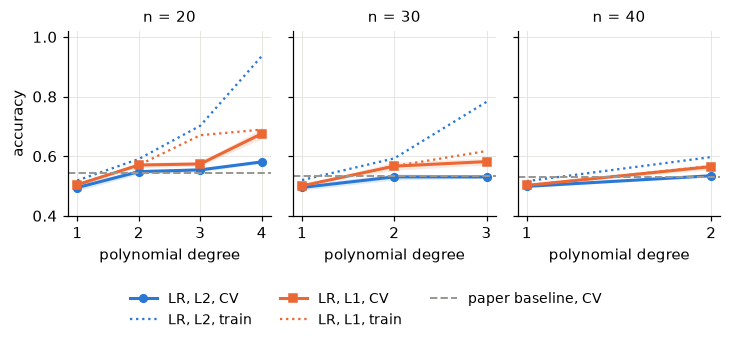

saved exp_figures/fig_lr_degree.pdf


In [13]:
tab, edge, ends = [], 0, {"strongest": [], "weakest": []}
for n in NS:
    r0 = CV.where(n=n, family="paper")[0]
    tab.append([
        n,
        NAME["paper"],
        "2 (raw X)",
        f"{r0['mean']:.3f} ± {r0['sd']:.3f}",
        f"{r0['train']:.3f}",
        "",
        "",
    ])
    for d in range(1, G["MAX_DEG"][n] + 1):
        for fam in ("lr_l2", "lr_l1"):
            rs = [r for r in CV.where(n=n, family=fam, sub=f"deg{d}")]
            b = max(rs, key=lambda r: r["mean"])
            Cs = sorted(r["params"]["C"] for r in rs)
            e = b["params"]["C"] in (Cs[0], Cs[-1])
            edge += e
            if e:
                ends["strongest" if b["params"]["C"] == Cs[0] else "weakest"].append(b["mean"])
            nnz = np.mean([p["nnz"] for p in b["post"]])
            nf = b["post"][0]["n_feats"]
            tab.append([
                n,
                NAME[fam],
                d,
                f"{b['mean']:.3f} ± {b['sd']:.3f}",
                f"{b['train']:.3f}",
                f"C = {b['params']['C']:g}" + (" (edge of grid)" if e else ""),
                f"{nnz:.0f} / {nf}",
            ])
display(
    Markdown(
        md_table(
            [
                "n",
                "model",
                "degree",
                "CV accuracy (mean ± sd over folds)",
                "train accuracy",
                "best C",
                "nonzero weights / features",
            ],
            tab,
        )
    )
)
ncell = len([t for t in tab if t[1] != NAME["paper"]])
print(
    f"{edge} of {ncell} (degree, penalty) cells chose a C on the edge of its grid: "
    + "; ".join(
        f"{len(v)} at the {k}-penalty end (best CV accuracy among them {max(v):.3f})"
        for k, v in ends.items()
        if v
    )
    + ". At the strongest end a larger penalty only shrinks a model towards a constant prediction"
    " (chance); at the weakest end a smaller one was not tried."
)

fig, axes = plt.subplots(1, 3, figsize=(6.75, 2.6), sharey=True)
for ax, n in zip(axes, NS):
    degs = list(range(1, G["MAX_DEG"][n] + 1))
    for fam in ("lr_l2", "lr_l1"):
        bs = [max(CV.where(n=n, family=fam, sub=f"deg{d}"), key=lambda r: r["mean"]) for d in degs]
        m, s = np.array([b["mean"] for b in bs]), np.array([b["sd"] for b in bs])
        ax.plot(degs, m, marker=MK[fam], color=COL[fam], label=f"{NAME[fam]}, CV")
        ax.fill_between(degs, m - s, m + s, color=COL[fam], alpha=0.15, lw=0)
        ax.plot(
            degs,
            [b["train"] for b in bs],
            ls=":",
            color=COL[fam],
            lw=1.5,
            label=f"{NAME[fam]}, train",
        )
    ax.axhline(
        CV.where(n=n, family="paper")[0]["mean"],
        color=GRAY,
        ls="--",
        lw=1.3,
        label="paper baseline, CV",
    )
    ax.set_title(f"n = {n}")
    ax.set_xlabel("polynomial degree")
    ax.set_xticks(degs)
    ax.set_ylim(0.40, 1.02)
axes[0].set_ylabel("accuracy")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=3)
fig.tight_layout()
savefig(fig, "fig_lr_degree")

## 3. Polynomial logistic regression of degree ≥ n (kernel)

The mock paper's Figure 1 fits polynomial logistic regression up to degree 10 with a kernel and stays near 55 %. For n = 20, 30, 40 that is below n. On the n-bit cube a monomial uses each bit at most once, so there are $2^n$ of them, and a polynomial of degree $d \geq n$ with a constant term can represent **every** function of the bits. So at $d \geq n$ the model class cannot be the limit; the question is whether such a model *learns* from the available rows. We use the **paper's own kernel** (that of `PolynomialFeatures(d)` on the bits, `C = 0.85`), trained in the dual so the monomials are never built, on the same folds as everything else, at $d = 10$ (the paper's largest degree, a replication), $d = n$ and $d = 2n$ (beyond $n$ only the weighting of the monomials changes, not what can be represented). No sweep. *Hypothesis:* such a kernel spreads its weight over thousands of monomials of order 4 to 9 and cannot single out the few relevant bits, so it fits the training rows without generalising; the train/CV gap tests it.

kernel tests passed


| n | kernel LR | train accuracy | CV accuracy (mean ± sd) | paired difference to the paper baseline [95% interval] | kernel value of two typical rows (n/2 bits agree; 1 = a row with itself) |
|---|---|---|---|---|---|
| 20 | degree 10 | 0.985 | 0.590 ± 0.010 | +0.046 [+0.028, +0.065] | 1e-04 |
| 20 | degree 20 | 1.000 | 0.595 ± 0.006 | +0.051 [+0.036, +0.066] | 1e-06 |
| 20 | degree 40 | 1.000 | 0.572 ± 0.006 | +0.028 [+0.013, +0.043] | 7e-09 |
| 30 | degree 10 | 1.000 | 0.549 ± 0.007 | +0.018 [+0.000, +0.035] | 2e-05 |
| 30 | degree 30 | 1.000 | 0.531 ± 0.005 | -0.001 [-0.021, +0.019] | 1e-09 |
| 30 | degree 60 | 1.000 | 0.505 ± 0.003 | -0.027 [-0.051, -0.003] | 5e-13 |
| 40 | degree 10 | 1.000 | 0.538 ± 0.008 | +0.008 [-0.007, +0.022] | 5e-06 |
| 40 | degree 40 | 1.000 | 0.502 ± 0.000 | -0.029 [-0.035, -0.023] | 1e-12 |
| 40 | degree 80 | 1.000 | 0.502 ± 0.000 | -0.029 [-0.035, -0.023] | 4e-17 |

**Fold 0 only: does a different `C` rescue the kernel at degree n?**

| n | kernel LR | C | train accuracy | held-out accuracy (fold 0) |
|---|---|---|---|---|
| 20 | degree 20 | 0.1 | 0.998 | 0.545 |
| 20 | degree 20 | 10 | 1.000 | 0.598 |
| 20 | degree 20 | 1000 | 1.000 | 0.603 |
| 30 | degree 30 | 0.1 | 1.000 | 0.501 |
| 30 | degree 30 | 10 | 1.000 | 0.546 |
| 30 | degree 30 | 1000 | 1.000 | 0.550 |
| 40 | degree 40 | 0.1 | 1.000 | 0.502 |
| 40 | degree 40 | 10 | 1.000 | 0.502 |
| 40 | degree 40 | 1000 | 1.000 | 0.502 |

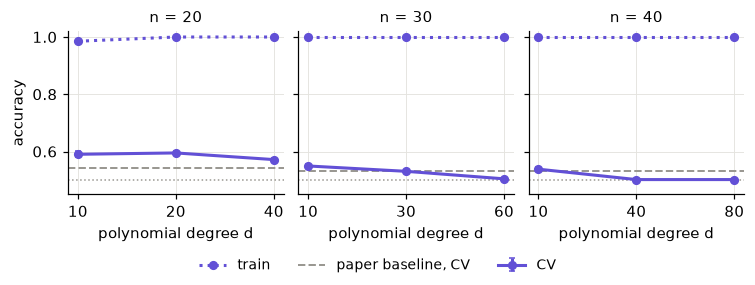

saved exp_figures/fig_kernel_degree.pdf


In [14]:
# ---- tests. (a) The Gram matrix of ALL 2^6 points has rank 2^6 exactly when d >= n (here n = 6),
# and rank sum_{s<=d} C(6,s) below that.
_P = np.array(list(itertools.product([-1.0, 1.0], repeat=6)))
for _d in (3, 5, 6, 7, 12):
    assert np.linalg.matrix_rank(KernelPolyLR(_d, 1)._gram(_P, _P)) == min(
        64, sum(comb(6, s) for s in range(_d + 1))
    ), f"rank at d={_d}"
# (b) the kernel is the inner product of PolynomialFeatures(d): compare with the explicit features
# at n = 5, d = 3 (the features of x are those of its bits)
_Q = _P[:, :5][::2]
_F = PolynomialFeatures(3).fit_transform(_Q)
_E = _F @ _F.T
_K = KernelPolyLR(3, 1)._gram(_Q, _Q)
assert np.allclose(_K, _E / np.diag(_E)[0], atol=1e-9), "kernel differs from PolynomialFeatures"
# (c) the dual solver agrees with sklearn's LogisticRegression on the explicit feature map of the
# same kernel (eigen-decomposition of the Gram matrix)
_r = np.random.default_rng(0)
_B = _r.choice([-1.0, 1.0], (80, 8))
_y = ((_B[:, 0] * _B[:, 1] > 0) ^ (_r.random(80) < 0.1)).astype(int)
for _d in (3, 8):
    _m = KernelPolyLR(_d, 0.85, maxiter=5000).fit(_B, _y)
    _w, _U = np.linalg.eigh(_m._gram(_B, _B))
    _k = _w > 1e-12 * _w.max()
    _F = _U[:, _k] * np.sqrt(_w[_k])
    _sk = LogisticRegression(C=0.85, tol=1e-10, max_iter=20000).fit(_F, _y)
    assert (
        np.abs(_m.f_train_ - (_F @ _sk.coef_[0] + _sk.intercept_[0])).max() < 1e-2
    ), f"dual solver differs from sklearn at d={_d}"
print("kernel tests passed")

for n in NS:
    for d in G["KP_DEGS"][n]:
        cv_config(
            n,
            "KPOLY",
            "kpoly",
            "all",
            f"deg{d}",
            dict(deg=d, C=G["KP_C"]),
            post=lambda m: dict(iters=m.iters_),
        )
tab = []
for n in NS:
    base = CV.where(n=n, family="paper")[0]
    for d in G["KP_DEGS"][n]:
        r = CV.where(n=n, family="kpoly", sub=f"deg{d}")[0]
        tab.append([
            n,
            f"degree {d}",
            f"{r['train']:.3f}",
            f"{r['mean']:.3f} ± {r['sd']:.3f}",
            "{mean:+.3f} [{lo:+.3f}, {hi:+.3f}]".format(**paired(r["folds"], base["folds"])),
            f"{paper_kernel_table(n, d)[n // 2]:.0e}",
        ])
display(
    Markdown(
        md_table(
            [
                "n",
                "kernel LR",
                "train accuracy",
                "CV accuracy (mean ± sd)",
                "paired difference to the paper baseline [95% interval]",
                "kernel value of two typical rows (n/2 bits agree; 1 = a row with itself)",
            ],
            tab,
        )
    )
)

# Is the regularisation to blame? Degree n, fold 0 only, C from 0.1 to 1000 (the paper's is 0.85; a
# larger C is a weaker penalty).
tab = []
for n in NS:
    for C in (0.1, 10, 1000):
        cv_config(
            n, "KPOLYC", "kpoly", "all", f"deg{n} C check, fold 0", dict(deg=n, C=C), folds=[0]
        )
    for r in sorted(CV.where(n=n, exp="KPOLYC"), key=lambda r: r["params"]["C"]):
        tab.append([
            n,
            f"degree {r['params']['deg']}",
            f"{r['params']['C']:g}",
            f"{r['train']:.3f}",
            f"{r['mean']:.3f}",
        ])
display(
    Markdown(
        "**Fold 0 only: does a different `C` rescue the kernel at degree n?**\n\n"
        + md_table(["n", "kernel LR", "C", "train accuracy", "held-out accuracy (fold 0)"], tab)
    )
)

fig, axes = plt.subplots(1, 3, figsize=(6.75, 2.5), sharey=True, layout="constrained")
for ax, n in zip(axes, NS):
    base = CV.where(n=n, family="paper")[0]
    rs = [CV.where(n=n, family="kpoly", sub=f"deg{d}")[0] for d in G["KP_DEGS"][n]]
    xs = range(len(rs))
    ax.errorbar(
        xs,
        [r["mean"] for r in rs],
        [r["sd"] for r in rs],
        marker="o",
        color=COL["kpoly"],
        capsize=2,
        label="CV",
    )
    ax.plot(xs, [r["train"] for r in rs], ls=":", marker="o", color=COL["kpoly"], label="train")
    ax.axhline(base["mean"], color=GRAY, ls="--", lw=1.3, label="paper baseline, CV")
    ax.axhline(0.5, color=GRAY, ls=":", lw=1)
    ax.set_xticks(list(xs))
    ax.set_xticklabels([str(d) for d in G["KP_DEGS"][n]])
    ax.set_xlabel("polynomial degree d")
    ax.set_title(f"n = {n}")
    ax.set_ylim(0.45, 1.02)
axes[0].set_ylabel("accuracy")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=3)
savefig(fig, "fig_kernel_degree")

## 4. Trees, forests, gradient boosting, and a small K-means baseline

The paper only tried polynomials. A forest can find useful feature combinations that a single tree cannot, so depth, leaf size and features per split are tuned by the same CV. K-means is a deliberately small baseline: it helps only if the label is a function of *which region* of bit space a row is in. It is fitted on the training folds and used twice: each cluster predicts its training majority label, or the one-hot cluster id is the only input to a logistic regression.

In [15]:
for n in NS:
    for d in G["DT_DEPTH"]:
        for l in G["DT_LEAF"]:
            cv_config(n, "TREE", "dtree", "all", "dtree", dict(max_depth=d, msl=l))
    for f in G["RF_MAXF"]:
        for l in G["RF_LEAF"]:
            cv_config(n, "TREE", "rf", "all", "rf", dict(max_features=f, msl=l))
    for d in G["HGB_DEPTH"]:
        cv_config(n, "TREE", "hgb", "all", "hgb", dict(max_depth=d))
    for k in G["KM_K"]:
        cv_config(n, "KM", "kmeans_major", "all", "kmeans_major", dict(k=k))
        cv_config(n, "KM", "kmeans_onehot", "all", "kmeans_onehot", dict(k=k))

## 5. MLPs from scratch

scikit-learn MLP, Adam, early stopping on a 10 % hold-out inside each training fold, long patience (a parity-like target can sit on a plateau at 50 % first). Two networks, no wider search: a small 2 x 128 net on all five folds, and one 4 x 512 net (KryptoNet's shape) on **fold 0 only**, because it is slow on a laptop CPU, with a capped budget (patience 15, at most 60 epochs). A single fold has no paired interval, so it is compared with the other models on that same fold.

In [16]:
MLP_GRID = [dict(h=h, alpha=a) for h in G["MLP_H"] for a in G["MLP_ALPHA"]]
for n in NS:
    for p in MLP_GRID:
        cv_config(n, "MLP", "mlp", "all", "mlp", p, post=lambda m: dict(epochs=int(m.n_iter_)))
    if RUN_KRYPTONET_SIZED:
        run(
            CV,
            f"MLP|{n}|mlp|kryptonet-sized|fold0",
            lambda: cv_eval(
                lambda: MLPClassifier(
                    (512, 512, 512, 512),
                    alpha=G["MLP_ALPHA"][0],
                    early_stopping=True,
                    n_iter_no_change=G["KN_PATIENCE"],
                    max_iter=G["KN_MAXITER"],
                    random_state=SEED,
                ),
                n,
                folds=(0,),
            ),
            exp="MLP",
            n=n,
            family="mlp",
            cond="all",
            sub="4x512 (fold 0 only)",
            params=dict(h=[512] * 4),
        )

| n | model (best setting by CV mean) | CV accuracy (mean ± sd over folds) | train accuracy | setting |
|---|---|---|---|---|
| 20 | paper baseline (quadratic LR), degree 2 | 0.544 ± 0.010 | 0.592 | {"deg": 2, "C": 0.85} |
| 20 | LR, L2, degree 4 | 0.581 ± 0.004 | 0.936 | {"deg": 4, "C": 0.001} |
| 20 | LR, L1, degree 4 | 0.675 ± 0.017 | 0.689 | {"deg": 4, "C": 0.01} |
| 20 | decision tree | 0.690 ± 0.079 | 1.000 | {"max_depth": null, "msl": 1} |
| 20 | random forest | 0.824 ± 0.023 | 0.981 | {"max_features": 1.0, "msl": 5} |
| 20 | gradient boosting | 0.749 ± 0.023 | 0.881 | {"max_depth": null} |
| 20 | K-means, cluster majority | 0.506 ± 0.007 | 0.512 | {"k": 8} |
| 20 | K-means, one-hot + LR | 0.506 ± 0.007 | 0.512 | {"k": 8} |
| 20 | MLP | 0.851 ± 0.023 | 0.985 | {"h": [128, 128], "alpha": 0.01} |
| 30 | paper baseline (quadratic LR), degree 2 | 0.532 ± 0.011 | 0.596 | {"deg": 2, "C": 0.85} |
| 30 | LR, L2, degree 2 | 0.531 ± 0.010 | 0.593 | {"deg": 2, "C": 0.01} |
| 30 | LR, L1, degree 3 | 0.582 ± 0.011 | 0.617 | {"deg": 3, "C": 0.01} |
| 30 | decision tree | 0.573 ± 0.089 | 0.923 | {"max_depth": 12, "msl": 1} |
| 30 | random forest | 0.784 ± 0.028 | 0.999 | {"max_features": 1.0, "msl": 5} |
| 30 | gradient boosting | 0.695 ± 0.045 | 0.853 | {"max_depth": null} |
| 30 | K-means, cluster majority | 0.509 ± 0.007 | 0.525 | {"k": 32} |
| 30 | K-means, one-hot + LR | 0.505 ± 0.008 | 0.543 | {"k": 128} |
| 30 | MLP | 0.660 ± 0.025 | 0.965 | {"h": [128, 128], "alpha": 0.01} |
| 40 | paper baseline (quadratic LR), degree 2 | 0.531 ± 0.003 | 0.600 | {"deg": 2, "C": 0.85} |
| 40 | LR, L2, degree 2 | 0.534 ± 0.004 | 0.597 | {"deg": 2, "C": 0.01} |
| 40 | LR, L1, degree 2 | 0.565 ± 0.011 | 0.567 | {"deg": 2, "C": 0.01} |
| 40 | decision tree | 0.528 ± 0.028 | 0.875 | {"max_depth": 12, "msl": 1} |
| 40 | random forest | 0.786 ± 0.024 | 1.000 | {"max_features": 1.0, "msl": 5} |
| 40 | gradient boosting | 0.674 ± 0.053 | 0.775 | {"max_depth": null} |
| 40 | K-means, cluster majority | 0.506 ± 0.006 | 0.508 | {"k": 8} |
| 40 | K-means, one-hot + LR | 0.505 ± 0.007 | 0.508 | {"k": 8} |
| 40 | MLP | 0.864 ± 0.041 | 0.987 | {"h": [128, 128], "alpha": 0.01} |

**4 x 512 MLP, fold 0 only** (one fold: compare the numbers, there is no interval).

| n | 4 x 512 MLP, fold-0 accuracy | 2 x 128 MLP, same fold | best generic model, same fold | 4 x 512 train accuracy | minutes |
|---|---|---|---|---|---|
| 20 | 0.932 | 0.848 ({"h": [128, 128], "alpha": 0.01}) | 0.848 (MLP) | 0.994 | 2.5 |
| 30 | 0.947 | 0.643 ({"h": [128, 128], "alpha": 0.01}) | 0.808 (random forest) | 0.995 | 6.2 |
| 40 | 0.944 | 0.899 ({"h": [128, 128], "alpha": 0.01}) | 0.899 (MLP) | 0.991 | 8.0 |

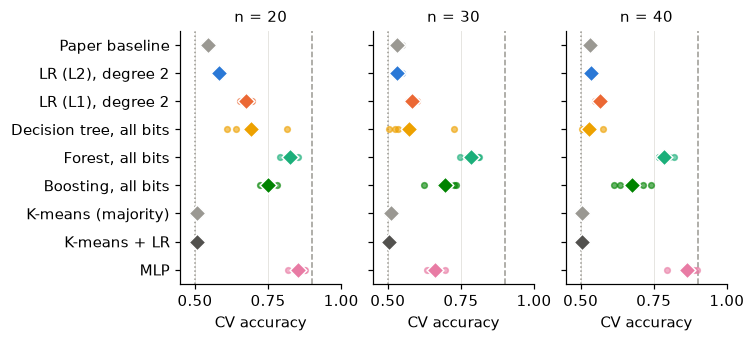

saved exp_figures/fig_generic.pdf


*Small dots: the five individual folds. Diamond: mean. Dotted line: chance (0.5). Dashed line: the 0.9 target. Each family is shown at its best setting by CV mean.*

In [17]:
# ---- generic models on all bits: best setting of each family (CV)
GENERIC = ("paper", "lr_l2", "lr_l1", "dtree", "rf", "hgb", "kmeans_major", "kmeans_onehot", "mlp")


def best_generic(n):
    out = []
    for fam in GENERIC:
        gs = [g for g in groups(n) if g["key"][0] == fam and g["key"][1] == "all"]
        if gs:
            out.append(max(gs, key=lambda g: g["best"]["mean"]))
    return out


def top_generic(n):
    # the paper baseline is a reference, not a candidate
    return max(
        (g for g in best_generic(n) if g["key"][0] != "paper"), key=lambda g: g["best"]["mean"]
    )


tab = []
for n in NS:
    for g in best_generic(n):
        b = g["best"]
        tab.append([
            n,
            kname(g["key"]),
            f"{b['mean']:.3f} ± {b['sd']:.3f}",
            f"{b['train']:.3f}",
            json.dumps(b["params"]),
        ])
display(
    Markdown(
        md_table(
            [
                "n",
                "model (best setting by CV mean)",
                "CV accuracy (mean ± sd over folds)",
                "train accuracy",
                "setting",
            ],
            tab,
        )
    )
)

kn = {r["n"]: r for r in CV.rows.values() if r["sub"].startswith("4x512")}
if kn:
    tab = []
    for n in NS:
        r = kn[n]
        mlp = [g for g in best_generic(n) if g["key"][0] == "mlp"][0]["best"]
        top = top_generic(n)
        tab.append([
            n,
            f"{r['folds'][0]:.3f}",
            f"{mlp['folds'][0]:.3f} ({json.dumps(mlp['params'])})",
            f"{top['best']['folds'][0]:.3f} ({NAME[top['key'][0]]})",
            f"{r['train']:.3f}",
            f"{r['secs'] / 60:.1f}",
        ])
    display(
        Markdown(
            "**4 x 512 MLP, fold 0 only** (one fold: compare the numbers, there is no"
            " interval).\n\n"
            + md_table(
                [
                    "n",
                    "4 x 512 MLP, fold-0 accuracy",
                    "2 x 128 MLP, same fold",
                    "best generic model, same fold",
                    "4 x 512 train accuracy",
                    "minutes",
                ],
                tab,
            )
        )
    )

fig, axes = plt.subplots(1, 3, figsize=(6.75, 3.0), sharey=True, layout="constrained")
for ax, n in zip(axes, NS):
    gs = best_generic(n)
    for i, g in enumerate(gs):
        fam = g["key"][0]
        f = g["best"]["folds"]
        ax.scatter(f, [i] * len(f), s=14, color=COL[fam], alpha=0.6, zorder=3, marker="o")
        ax.scatter(
            [g["best"]["mean"]], [i], s=60, color=COL[fam], marker="D", edgecolor="white", zorder=4
        )
    ax.axvline(0.5, color=GRAY, ls=":", lw=1)
    ax.axvline(0.9, color=GRAY, ls="--", lw=1)
    ax.set_yticks(range(len(gs)))
    ax.set_yticklabels([sname(g["key"]) for g in gs])
    ax.grid(axis="y", alpha=0)
    ax.set_xlim(0.45, 1.0)
    ax.set_xticks([0.5, 0.75, 1.0])
    ax.set_title(f"n = {n}")
    ax.set_xlabel("CV accuracy")
axes[0].set_ylim(len(best_generic(NS[0])) - 0.5, -0.5)
savefig(fig, "fig_generic")
display(
    Markdown(
        "*Small dots: the five individual folds. Diamond: mean. Dotted line: chance (0.5). Dashed"
        " line: the 0.9 target. Each family is shown at its best setting by CV mean.*"
    )
)

## 6. The bit selector

Section 7 puts a feature selector in front of a forest and of a polynomial LR. It is a heuristic, and it is judged by cross-validation, not by a guarantee. It runs inside every training fold, on that fold's training rows only. With $s = 2y - 1$ and bits $b_j \in \{\pm 1\}$:

1. **Gate.** The pair $(a, b)$ maximising $|\hat E[s\, b_a b_b]|$.
2. **Scan.** For every set $T$ of 1 to 4 other bits, $c(T) = \hat E[s\, b_a b_b \prod_{j \in T} b_j]$. Keep $|c(T)| > 4/\sqrt N$ (four standard errors).
3. **Mass and selection.** $\text{mass}(j) = \sum_{T \ni j} c(T)^2$ over the kept coefficients. Keep the gate pair plus every bit with mass $> 0.02$, at most 14 bits in all.

The 4-sigma test, the mass threshold 0.02 and the cap of 14 are choices, not derived quantities, and a scan over thousands of coefficients has no family-wise error control. **Limits:** only terms that contain the gate pair and at most 4 further bits are seen; a label function without a usable pair term (a parity of several bits, say) gives a noise gate and the selector finds nothing. The shuffled-label check below measures how many bits it invents on pure noise, and section 10.2 repeats that for the final pipeline.

In [18]:
# ---- the selector
@lru_cache(None)
def _triu(m):
    return np.triu_indices(m, 1)


def scan_core(R, z, maxdeg):
    # mean(z * prod(R[:, T])) for EVERY subset T of the columns of R with |T| = 1..maxdeg, via a few
    # matrix products (maxdeg <= 4). Returns {k: (subsets as an array of column indices,
    # coefficients)}.
    N, m = R.shape
    R = np.ascontiguousarray(R, dtype=np.float32)
    z = np.asarray(z, dtype=np.float32)
    assert maxdeg <= 4
    out = {1: (np.arange(m)[:, None], (R.T @ z) / N)}
    if maxdeg >= 2:
        M = (R * z[:, None]).T @ R / N
        iu = _triu(m)
        out[2] = (np.stack(iu, 1), M[iu])
    if maxdeg >= 3:
        cs, vs = [], []
        for i in range(m - 2):
            Rs = R[:, i + 1 :]
            M = (Rs * (z * R[:, i])[:, None]).T @ Rs / N
            a, b = _triu(m - i - 1)
            cs.append(np.stack([np.full(len(a), i), a + i + 1, b + i + 1], 1))
            vs.append(M[a, b])
        out[3] = (np.concatenate(cs), np.concatenate(vs))
    if maxdeg >= 4:
        cs, vs = [], []
        for i in range(m - 3):
            for j in range(i + 1, m - 2):
                Rs = R[:, j + 1 :]
                M = (Rs * (z * R[:, i] * R[:, j])[:, None]).T @ Rs / N
                a, b = _triu(m - j - 1)
                cs.append(
                    np.stack([np.full(len(a), i), np.full(len(a), j), a + j + 1, b + j + 1], 1)
                )
                vs.append(M[a, b])
        out[4] = (np.concatenate(cs), np.concatenate(vs))
    return out


Z_FLOOR = 4.0  # only coefficients above this many standard errors are stored (and used)


def scan_bits(B, y, maxdeg=4):
    # steps 1 and 2 of section 6. Returns everything the selection rules need: the gate, its
    # coefficient, and every scanned coefficient above Z_FLOOR standard errors. No selection rule is
    # applied here.
    N, n = B.shape
    s = (2.0 * y - 1).astype(np.float32)
    C = (B * s[:, None]).T @ B / N
    np.fill_diagonal(C, 0.0)
    a, b = np.unravel_index(np.argmax(np.abs(C)), C.shape)
    pair = (int(min(a, b)), int(max(a, b)))
    rest = np.array([i for i in range(n) if i not in pair])
    res = scan_core(B[:, rest], s * B[:, pair[0]] * B[:, pair[1]], maxdeg)
    thr = Z_FLOOR / np.sqrt(N)
    hits = []
    for k, (cm, cf) in res.items():
        for i in np.where(np.abs(cf) > thr)[0]:
            hits.append([[int(rest[q]) for q in cm[i]], float(cf[i])])
    return dict(pair=list(pair), gate_coef=float(C[a, b]), hits=hits, N=int(N), n=int(n))


def choose_bits(res, max_bits=14, mass_thr=0.02):
    N, n, pair = res["N"], res["n"], res["pair"]
    sq = np.sqrt(N)
    mass = np.zeros(n)
    for T, c in res["hits"]:
        if abs(c) > 4.0 / sq:
            for t in T:
                mass[t] += c * c
    ranked = [int(i) for i in np.argsort(-mass) if mass[i] > mass_thr and i not in pair]
    return dict(
        bits=sorted(pair + ranked[: max_bits - 2]),
        pair=pair,
        mass=[round(float(v), 5) for v in mass],
        gate_z=abs(res["gate_coef"]) * sq,
    )


_SCAN_PATH = f"{OUT}/scan_cache.json"
_SCAN = json.load(open(_SCAN_PATH)) if os.path.exists(_SCAN_PATH) else {}


def get_scan(B, y):
    # scan_bits with an on-disk cache keyed by the content of (B, y): the same training rows are
    # never scanned twice
    key = (
        hashlib.md5(np.ascontiguousarray(B).tobytes() + y.astype(np.int8).tobytes()).hexdigest()[
            :16
        ]
        + f"|{B.shape[0]}x{B.shape[1]}|z{Z_FLOOR}"
    )
    if key not in _SCAN:
        _SCAN[key] = scan_bits(B, y)
        json.dump(_SCAN, open(_SCAN_PATH, "w"))
    return _SCAN[key]


class BitModel:
    # wraps any estimator: scan + select on the rows it is FITTED on, then fit the estimator on
    # those columns only. If nothing is selected it predicts the training majority class.
    def __init__(self, base):
        self.base = base

    def fit(self, B, y):
        self.scan_ = get_scan(B, y)
        sel = choose_bits(self.scan_)
        self.cols_, self.pair_, self.mass_, self.gate_z_ = (
            sel["bits"],
            sel["pair"],
            sel["mass"],
            sel["gate_z"],
        )
        self.const_ = None if self.cols_ else int(y.mean() >= 0.5)
        if self.cols_:
            self.base.fit(B[:, self.cols_], y)
        return self

    def predict(self, B):
        return (
            np.full(len(B), self.const_)
            if self.const_ is not None
            else self.base.predict(B[:, self.cols_])
        )

In [19]:
# ---- tests
def _brute_bits(B, y, maxdeg=4, mass_thr=0.02, max_bits=14):
    # a plain loop over all subsets: a slow reference implementation, used only to test scan_bits
    N, n = B.shape
    s = 2.0 * y - 1
    C = (B * s[:, None]).T @ B / N
    np.fill_diagonal(C, 0.0)
    a, b = np.unravel_index(np.argmax(np.abs(C)), C.shape)
    pair = (int(min(a, b)), int(max(a, b)))
    z = (s * B[:, pair[0]] * B[:, pair[1]]).astype(np.float32)
    rest = [i for i in range(n) if i not in pair]
    mass, thr = np.zeros(n), 4.0 / np.sqrt(N)
    for k in range(1, maxdeg + 1):
        for c in itertools.combinations(rest, k):
            coef = float((z * np.prod(B[:, list(c)], axis=1)).mean())
            if abs(coef) > thr:
                for t in c:
                    mass[t] += coef**2
    ranked = [int(i) for i in np.argsort(-mass) if mass[i] > mass_thr and i not in pair]
    return sorted(list(pair) + ranked[: max_bits - 2]), mass


_rng = np.random.default_rng(1)
_n, _N = 12, 700
_B = _rng.choice([-1.0, 1.0], (_N, _n)).astype(np.float32)
_f = (
    _B[:, 0] * _B[:, 1] * _B[:, 2]
    + 0.8 * _B[:, 0] * _B[:, 1] * _B[:, 5] * _B[:, 6]
    + 0.6 * _B[:, 0] * _B[:, 1]
)
_y = ((_f + _rng.normal(0, 0.3, _N)) > 0).astype(int)
_bits_ref, _mass_ref = _brute_bits(_B, _y)
_res = scan_bits(_B, _y)
assert choose_bits(_res)["bits"] == _bits_ref, "fast scan disagrees with the plain loop"
assert (
    np.abs(np.array(choose_bits(_res)["mass"]) - _mass_ref).max() < 1e-4
), "mass differs from the plain loop"
assert set(_res["pair"]) == {0, 1} and {0, 1, 2, 5, 6} <= set(
    _bits_ref
), "planted gate terms not found"
# a label that is a function of one pair only: exactly that pair is selected
_B2 = np.random.default_rng(2).choice([-1.0, 1.0], (7680, 20)).astype(np.float32)
_y2 = ((_B2[:, 3] * _B2[:, 5] > 0) ^ (np.random.default_rng(3).random(7680) < 0.03)).astype(int)
_r2 = scan_bits(_B2, _y2)
assert _r2["pair"] == [3, 5] and choose_bits(_r2)["bits"] == [3, 5]
print("selector tests passed")

selector tests passed


In [20]:
# ---- shuffled-label null: real inputs, the training rows of fold 0, labels permuted. Nothing is
# relevant, so every selected bit beyond the gate is false.
for n in NS:
    X, B, y = load(n)
    tr0 = FOLDS[n][0][0]
    for rep in range(G["NULL_REPS"]):

        def job():
            t0 = time.time()
            res = scan_bits(B[tr0], np.random.default_rng(rep).permutation(y[tr0]))
            sel = choose_bits(res)
            return dict(
                mean=0.0,
                sd=0.0,
                secs=round(time.time() - t0, 1),
                hits4=len(res["hits"]),
                n_sel=len(sel["bits"]),
                gate_z=sel["gate_z"],
            )

        run(NUL, f"null|{n}|{rep}", job, quiet=True, exp="NULL", n=n, rep=rep)
tab = []
for n in NS:
    rs = NUL.where(n=n)
    m_scan = comb(n - 2, 1) + comb(n - 2, 2) + comb(n - 2, 3) + comb(n - 2, 4)
    tab.append([
        n,
        len(rs),
        f"{np.mean([r['hits4'] for r in rs]):.1f} / {m_scan * 2 * stats.norm.sf(4):.1f}",
        f"{np.mean([r['n_sel'] for r in rs]):.1f}",
        f"{np.mean([r['gate_z'] for r in rs]):.1f}",
    ])
display(
    Markdown(
        "**Selector on shuffled labels** (every selected bit beyond the 2 gate bits is false).\n\n"
        + md_table(
            [
                "n",
                "runs",
                "scan hits above 4 sd: observed / expected by chance",
                "bits selected (2 = the gate alone)",
                "gate z (mean)",
            ],
            tab,
        )
    )
)

**Selector on shuffled labels** (every selected bit beyond the 2 gate bits is false).

| n | runs | scan hits above 4 sd: observed / expected by chance | bits selected (2 = the gate alone) | gate z (mean) |
|---|---|---|---|---|
| 20 | 20 | 0.3 / 0.3 | 2.0 | 3.0 |
| 30 | 20 | 1.6 / 1.5 | 2.0 | 3.2 |
| 40 | 20 | 5.0 / 5.3 | 2.0 | 3.4 |

## 7. Selector + forest, and selector + polynomial LR

Does a model on the selected bits beat the generic models on all bits, when the selector never sees the held-out fold? Two second-stage models, same folds: a forest, and logistic regression on **all** monomials of the selected bits (a polynomial of degree k for k bits: the model class that the paper's degree-10 fits on all n bits could not reach). The selector runs inside each training fold (section 6).

| n | forest on selected bits, CV accuracy | bits selected (mean) | fold-to-fold overlap of the selected bits (Jaccard) | gate z (mean) | best generic model on all bits | paired difference to it [95% interval] |
|---|---|---|---|---|---|---|
| 20 | 0.958 ± 0.006 | 10.0 | 1.00 | 12.3 | MLP: 0.851 | +0.107 [+0.066, +0.147] |
| 30 | 0.962 ± 0.002 | 10.0 | 1.00 | 15.0 | random forest: 0.784 | +0.178 [+0.124, +0.232] |
| 40 | 0.960 ± 0.002 | 10.0 | 1.00 | 18.4 | MLP: 0.864 | +0.096 [+0.020, +0.173] |

**Polynomial logistic regression on all monomials of the selected bits** (with k bits this is a polynomial of degree k, so it can represent any function of them; best setting by CV).

| n | bits selected (mean) | best setting | train accuracy | CV accuracy | difference to the forest on the same bits [95% interval] | difference to the paper baseline [95% interval] |
|---|---|---|---|---|---|---|
| 20 | 10.0 | L1, C = 0.003 | 0.960 | 0.960 ± 0.006 | +0.002 [-0.001, +0.004] | +0.416 [+0.404, +0.427] |
| 30 | 10.0 | L1, C = 0.003 | 0.962 | 0.962 ± 0.002 | +0.000 [-0.001, +0.001] | +0.430 [+0.405, +0.455] |
| 40 | 10.0 | L2, C = 0.001 | 0.960 | 0.960 ± 0.002 | +0.000 [+0.000, +0.000] | +0.430 [+0.424, +0.436] |

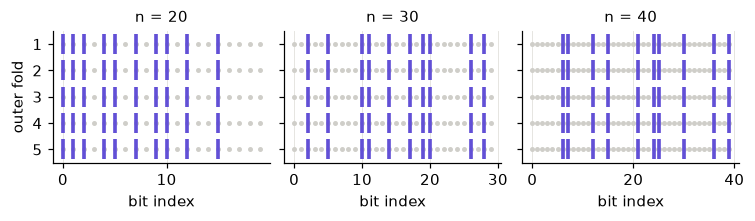

saved exp_figures/fig_selected_bits.pdf


*A bar marks a bit the selector chose in that outer fold; grey dots are all bit positions. Identical rows mean the same bits were found in every fold.*

In [21]:
def sel_post(m):
    return dict(
        bits=[int(b) for b in m.cols_], pair=m.pair_, gate_z=float(m.gate_z_), n_sel=len(m.cols_)
    )


def jaccard_mean(sets):
    sets = [set(s) for s in sets]
    v = [len(a & b) / max(len(a | b), 1) for a, b in itertools.combinations(sets, 2)]
    return float(np.mean(v)) if v else float("nan")


for n in NS:
    for f in G["SEL_RF_MAXF"]:
        for l in G["SEL_RF_LEAF"]:
            cv_config(n, "SEL", "rf", "sel", "rf", dict(max_features=f, msl=l), post=sel_post)


def sel_best(n):
    return [g for g in groups(n) if g["key"] == ("rf", "sel", "rf")][0]["best"]


# polynomial logistic regression restricted to the selected bits: all 2^k - 1 monomials of the k
# selected bits (degree k, so any function of those bits)
for n in NS:
    for pen in ("l2", "l1"):
        for C in G["C_L2" if pen == "l2" else "C_L1"]:
            cv_config(n, "SELPOLY", "lrfull", "sel", "lrfull", dict(pen=pen, C=C), post=sel_post)


tab = []
for n in NS:
    b = sel_best(n)
    gen = top_generic(n)
    pr = paired(b["folds"], gen["best"]["folds"])
    tab.append([
        n,
        f"{b['mean']:.3f} ± {b['sd']:.3f}",
        f"{np.mean([p['n_sel'] for p in b['post']]):.1f}",
        f"{jaccard_mean([p['bits'] for p in b['post']]):.2f}",
        f"{np.mean([p['gate_z'] for p in b['post']]):.1f}",
        f"{NAME[gen['key'][0]]}: {gen['best']['mean']:.3f}",
        f"{pr['mean']:+.3f} [{pr['lo']:+.3f}, {pr['hi']:+.3f}]",
    ])
display(
    Markdown(
        md_table(
            [
                "n",
                "forest on selected bits, CV accuracy",
                "bits selected (mean)",
                "fold-to-fold overlap of the selected bits (Jaccard)",
                "gate z (mean)",
                "best generic model on all bits",
                "paired difference to it [95% interval]",
            ],
            tab,
        )
    )
)

tab = []
for n in NS:
    g = [g for g in groups(n) if g["key"] == ("lrfull", "sel", "lrfull")][0]["best"]
    f = sel_best(n)
    base = CV.where(n=n, family="paper")[0]
    pf, pb = paired(g["folds"], f["folds"]), paired(g["folds"], base["folds"])
    tab.append([
        n,
        f"{np.mean([p['n_sel'] for p in g['post']]):.1f}",
        f"{g['params']['pen'].upper()}, C = {g['params']['C']:g}",
        f"{g['train']:.3f}",
        f"{g['mean']:.3f} ± {g['sd']:.3f}",
        f"{pf['mean']:+.3f} [{pf['lo']:+.3f}, {pf['hi']:+.3f}]",
        f"{pb['mean']:+.3f} [{pb['lo']:+.3f}, {pb['hi']:+.3f}]",
    ])
display(
    Markdown(
        "**Polynomial logistic regression on all monomials of the selected bits** (with k bits this"
        " is a polynomial of degree k, so it can represent any function of them; best setting by"
        " CV).\n\n"
        + md_table(
            [
                "n",
                "bits selected (mean)",
                "best setting",
                "train accuracy",
                "CV accuracy",
                "difference to the forest on the same bits [95% interval]",
                "difference to the paper baseline [95% interval]",
            ],
            tab,
        )
    )
)

fig, axes = plt.subplots(1, 3, figsize=(6.75, 1.9), sharey=True, layout="constrained")
for ax, n in zip(axes, NS):
    post = sel_best(n)["post"]
    for i, p in enumerate(post):
        # every bit position
        ax.scatter(np.arange(n), [i] * n, s=5, color="#cfcec9", zorder=2)
        ax.vlines(p["bits"], i - 0.38, i + 0.38, color=VIOLET, lw=2.4, zorder=3)
    ax.set_yticks(range(len(post)))
    ax.set_yticklabels([str(i + 1) for i in range(len(post))])
    ax.grid(axis="y", alpha=0)
    ax.set_title(f"n = {n}")
    ax.set_xlabel("bit index")
axes[0].set_ylabel("outer fold")
axes[0].set_ylim(len(sel_best(NS[0])["post"]) - 0.5, -0.5)
savefig(fig, "fig_selected_bits")
display(
    Markdown(
        "*A bar marks a bit the selector chose in that outer fold; grey dots are all bit positions."
        " Identical rows mean the same bits were found in every fold.*"
    )
)

**What is left after selection?** Descriptive checks on the dev rows only (nothing here feeds the pipeline or the locked test), for the bits the selector chose in every fold: do the other bits add anything, and are the remaining errors predictable from them?

In [22]:
from sklearn.metrics import roc_auc_score

tab = []
for n in NS:
    sets = {tuple(p["bits"]) for p in sel_best(n)["post"]}
    if len(sets) != 1:
        print(f"n={n}: the selected bits differ between folds, skipped")
        continue
    bits = list(sets.pop())
    rest = [i for i in range(n) if i not in bits]
    X, B, y = load(n)
    Bd, yd = B[DEV[n]], y[DEV[n]]
    P = PolynomialFeatures(len(bits), interaction_only=True, include_bias=False).fit_transform(
        Bd[:, bits]
    )
    skf = list(StratifiedKFold(K, shuffle=True, random_state=SEED).split(Bd, yd))

    def oof(F):
        pr = np.zeros(len(yd), int)
        for tr, va in skf:
            pr[va] = LogisticRegression(C=1.0, max_iter=300).fit(F[tr], yd[tr]).predict(F[va])
        return pr

    p1, p2 = oof(P), oof(np.hstack([P, Bd[:, rest]]))
    err = (p1 != yd).astype(int)
    pa = np.zeros(len(yd))
    for tr, va in skf:
        pa[va] = (
            HistGradientBoostingClassifier(
                max_depth=4, max_iter=150, learning_rate=0.05, random_state=SEED
            )
            .fit(Bd[tr][:, rest], err[tr])
            .predict_proba(Bd[va][:, rest])[:, 1]
        )
    order = np.argsort((Bd[:, rest] > 0).sum(1), kind="stable")
    fifth = len(order) // 5
    tab.append([
        n,
        f"{(p1 == yd).mean():.3f}",
        f"{(p2 == yd).mean():.3f}",
        f"{roc_auc_score(err, pa):.2f}",
        f"{err[order[:fifth]].mean():.3f} / {err[order[-fifth:]].mean():.3f}",
    ])
display(
    Markdown(
        md_table(
            [
                "n",
                "accuracy: all monomials of the selected bits",
                "... plus the other bits as linear terms",
                "AUC for predicting this model's errors from the other bits (0.5 = none)",
                "error rate: fifth of rows with fewest 1s among the other bits / most 1s",
            ],
            tab,
        )
    )
)

| n | accuracy: all monomials of the selected bits | ... plus the other bits as linear terms | AUC for predicting this model's errors from the other bits (0.5 = none) | error rate: fifth of rows with fewest 1s among the other bits / most 1s |
|---|---|---|---|---|
| 20 | 0.958 | 0.958 | 0.50 | 0.045 / 0.047 |
| 30 | 0.962 | 0.962 | 0.59 | 0.028 / 0.040 |
| 40 | 0.960 | 0.960 | 0.61 | 0.032 / 0.047 |

## 8. Paired comparison and the final pipeline

All candidates were scored on the same folds, so each is compared with the leader fold by fold (paired difference, Nadeau–Bengio 95 % interval). **Choice rule, fixed before looking at the locked test:** the final pipeline for each n is the candidate with the highest CV mean, excluding the paper baseline.

In [23]:
FINAL, TOPN = {}, 8
for n in NS:
    gs = groups(n)
    cands = [g for g in gs if g["key"][0] != "paper"]
    top = cands[0]
    FINAL[n] = top
    tab = []
    for i, g in enumerate(cands[:TOPN] + [g for g in gs if g["key"][0] == "paper"]):
        b = g["best"]
        pr = paired(b["folds"], top["best"]["folds"])
        verdict = "leader" if g is top else ("not distinguishable" if pr["hi"] >= 0 else "worse")
        tab.append([
            i + 1 if g["key"][0] != "paper" else "ref",
            kname(g["key"]),
            f"{b['mean']:.3f} ± {b['sd']:.3f}",
            f"{b['train']:.3f}",
            "" if g is top else f"{pr['mean']:+.3f} [{pr['lo']:+.3f}, {pr['hi']:+.3f}]",
            "" if g is top else f"{pr['wins']} of {pr['k']}",
            verdict,
        ])
    display(
        Markdown(
            f"**n = {n}**\n\n"
            + md_table(
                [
                    "rank",
                    "candidate (best setting by CV)",
                    "CV accuracy (mean ± sd over folds)",
                    "train",
                    "paired difference to leader [95% interval]",
                    "folds where it beats the leader",
                    "verdict",
                ],
                tab,
            )
        )
    )
    tied = [
        kname(g["key"])
        for g in cands[1:]
        if paired(g["best"]["folds"], top["best"]["folds"])["hi"] >= 0
    ]
    print(
        f"n={n}: selected {kname(top['key'])}  {json.dumps(top['best']['params'])};  not"
        f" distinguishable from it: {len(tied)} of {len(cands) - 1} other candidates"
        + (f" ({'; '.join(tied[:4])}{'...' if len(tied) > 4 else ''})" if tied else "")
    )

**n = 20**

| rank | candidate (best setting by CV) | CV accuracy (mean ± sd over folds) | train | paired difference to leader [95% interval] | folds where it beats the leader | verdict |
|---|---|---|---|---|---|---|
| 1 | LR on all monomials on selected bits | 0.960 ± 0.006 | 0.960 |  |  | leader |
| 2 | random forest on selected bits | 0.958 ± 0.006 | 0.960 | -0.002 [-0.004, +0.001] | 0 of 5 | not distinguishable |
| 3 | MLP | 0.851 ± 0.023 | 0.985 | -0.108 [-0.151, -0.066] | 0 of 5 | worse |
| 4 | random forest | 0.824 ± 0.023 | 0.981 | -0.136 [-0.185, -0.087] | 0 of 5 | worse |
| 5 | gradient boosting | 0.749 ± 0.023 | 0.881 | -0.211 [-0.252, -0.169] | 0 of 5 | worse |
| 6 | decision tree | 0.690 ± 0.079 | 1.000 | -0.270 [-0.409, -0.130] | 0 of 5 | worse |
| 7 | LR, L1, degree 4 | 0.675 ± 0.017 | 0.689 | -0.284 [-0.314, -0.255] | 0 of 5 | worse |
| 8 | LR, polynomial kernel, degree 20 | 0.595 ± 0.006 | 1.000 | -0.365 [-0.380, -0.350] | 0 of 5 | worse |
| ref | paper baseline (quadratic LR), degree 2 | 0.544 ± 0.010 | 0.592 | -0.416 [-0.427, -0.404] | 0 of 5 | worse |

n=20: selected LR on all monomials on selected bits  {"pen": "l1", "C": 0.003};  not distinguishable from it: 1 of 18 other candidates (random forest on selected bits)


**n = 30**

| rank | candidate (best setting by CV) | CV accuracy (mean ± sd over folds) | train | paired difference to leader [95% interval] | folds where it beats the leader | verdict |
|---|---|---|---|---|---|---|
| 1 | LR on all monomials on selected bits | 0.962 ± 0.002 | 0.962 |  |  | leader |
| 2 | random forest on selected bits | 0.962 ± 0.002 | 0.962 | -0.000 [-0.001, +0.001] | 0 of 5 | not distinguishable |
| 3 | random forest | 0.784 ± 0.028 | 0.999 | -0.178 [-0.232, -0.124] | 0 of 5 | worse |
| 4 | gradient boosting | 0.695 ± 0.045 | 0.853 | -0.267 [-0.352, -0.182] | 0 of 5 | worse |
| 5 | MLP | 0.660 ± 0.025 | 0.965 | -0.302 [-0.348, -0.257] | 0 of 5 | worse |
| 6 | LR, L1, degree 3 | 0.582 ± 0.011 | 0.617 | -0.380 [-0.400, -0.361] | 0 of 5 | worse |
| 7 | decision tree | 0.573 ± 0.089 | 0.923 | -0.389 [-0.553, -0.224] | 0 of 5 | worse |
| 8 | LR, L1, degree 2 | 0.566 ± 0.014 | 0.566 | -0.396 [-0.424, -0.367] | 0 of 5 | worse |
| ref | paper baseline (quadratic LR), degree 2 | 0.532 ± 0.011 | 0.596 | -0.430 [-0.455, -0.405] | 0 of 5 | worse |

n=30: selected LR on all monomials on selected bits  {"pen": "l1", "C": 0.003};  not distinguishable from it: 1 of 16 other candidates (random forest on selected bits)


**n = 40**

| rank | candidate (best setting by CV) | CV accuracy (mean ± sd over folds) | train | paired difference to leader [95% interval] | folds where it beats the leader | verdict |
|---|---|---|---|---|---|---|
| 1 | random forest on selected bits | 0.960 ± 0.002 | 0.960 |  |  | leader |
| 2 | LR on all monomials on selected bits | 0.960 ± 0.002 | 0.960 | +0.000 [+0.000, +0.000] | 0 of 5 | not distinguishable |
| 3 | MLP | 0.864 ± 0.041 | 0.987 | -0.096 [-0.173, -0.020] | 0 of 5 | worse |
| 4 | random forest | 0.786 ± 0.024 | 1.000 | -0.174 [-0.221, -0.127] | 0 of 5 | worse |
| 5 | gradient boosting | 0.674 ± 0.053 | 0.775 | -0.286 [-0.383, -0.189] | 0 of 5 | worse |
| 6 | LR, L1, degree 2 | 0.565 ± 0.011 | 0.567 | -0.396 [-0.416, -0.375] | 0 of 5 | worse |
| 7 | LR, polynomial kernel, degree 10 | 0.538 ± 0.008 | 1.000 | -0.422 [-0.435, -0.409] | 0 of 5 | worse |
| 8 | LR, L2, degree 2 | 0.534 ± 0.004 | 0.597 | -0.426 [-0.434, -0.419] | 0 of 5 | worse |
| ref | paper baseline (quadratic LR), degree 2 | 0.531 ± 0.003 | 0.600 | -0.430 [-0.436, -0.424] | 0 of 5 | worse |

n=40: selected random forest on selected bits  {"max_features": "sqrt", "msl": 1};  not distinguishable from it: 1 of 14 other candidates (LR on all monomials on selected bits)


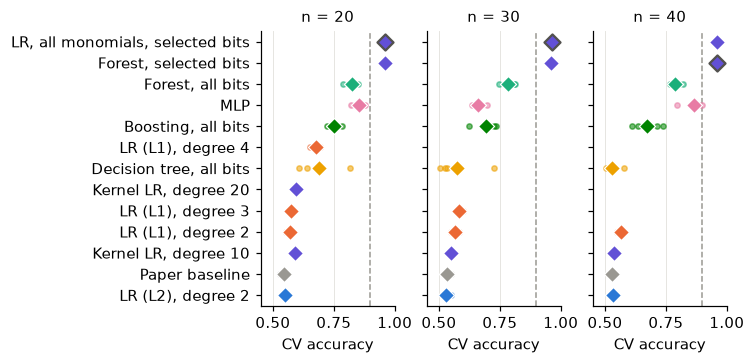

saved exp_figures/fig_cv_overview.pdf


*Small dots: the five folds. Diamond: mean. Dashed line: the 0.9 target. Dark outline: the pipeline chosen for that n (highest CV mean). Violet: models on the selected bits.*

In [24]:
UNION = {}
for n in NS:
    for g in [g for g in groups(n) if g["key"][0] != "paper"][:TOPN] + [
        g for g in groups(n) if g["key"][0] == "paper"
    ]:
        UNION.setdefault(g["key"], []).append(g["best"]["mean"])
# the same rows, in the same order, in every panel
ROW_ORDER = sorted(UNION, key=lambda k: -np.mean(UNION[k]))
fig, axes = plt.subplots(1, 3, figsize=(6.75, 3.2), sharey=True, layout="constrained")
for ax, n in zip(axes, NS):
    byk = {g["key"]: g for g in groups(n)}
    for i, key in enumerate(ROW_ORDER):
        if key not in byk:
            continue
        g = byk[key]
        fam = key[0]
        sel = key[1] != "all"
        f = g["best"]["folds"]
        col = VIOLET if sel else COL[fam]
        fin = key == FINAL[n]["key"]
        ax.scatter(f, [i] * len(f), s=12, color=col, alpha=0.55, zorder=3)
        ax.scatter(
            [g["best"]["mean"]],
            [i],
            s=55,
            color=col,
            marker="D",
            edgecolor=(INK if fin else "white"),
            linewidth=1.5 if fin else 0.8,
            zorder=4,
        )
    ax.axvline(0.9, color=GRAY, ls="--", lw=1)
    ax.set_yticks(range(len(ROW_ORDER)))
    ax.set_yticklabels([sname(k) for k in ROW_ORDER])
    ax.grid(axis="y", alpha=0)
    ax.set_title(f"n = {n}")
    ax.set_xlabel("CV accuracy")
    ax.set_xlim(0.45, 1.0)
    ax.set_xticks([0.5, 0.75, 1.0])
axes[0].set_ylim(len(ROW_ORDER) - 0.5, -0.5)
savefig(fig, "fig_cv_overview")
display(
    Markdown(
        "*Small dots: the five folds. Diamond: mean. Dashed line: the 0.9 target. Dark outline: the"
        " pipeline chosen for that n (highest CV mean). Violet: models on the selected bits.*"
    )
)

## 9. Learning curves

The top candidates of section 8 (different families or inputs) are trained on nested random subsets of the training folds and scored on the held-out fold, for the first three folds. For logistic regression, `C` multiplies the summed loss, so the same `C` penalises more strongly when there are fewer rows; at each size `C` is therefore scaled by (full training rows / rows used), which keeps the penalty per row fixed.

In [25]:
for k in [k for k, r in LC.rows.items() if r["family"] == "lrfull" and not k.endswith("|cs")]:
    # logistic-regression curves stored by an earlier version of this notebook (unscaled C): not
    # used
    del LC.rows[k]
LC_CANDS = {}
for n in NS:
    seen, pick = set(), []
    for g in groups(n):
        k2 = g["key"][:2]
        if g["key"][0] == "paper" or k2 in seen:
            continue
        seen.add(k2)
        pick.append(g)
        if len(pick) == G["LC_TOP"]:
            break
    LC_CANDS[n] = pick
    for g in pick:
        fam, cond, sub = g["key"]
        p = g["best"]["params"]
        suf = "|cs" if fam == "lrfull" else ""
        for size in G["LC_SIZES"]:
            if size >= FOLD_TRAIN[n]:
                continue
            ps = dict(p, C=p["C"] * FOLD_TRAIN[n] / size) if fam == "lrfull" else p
            run(
                LC,
                f"lc|{n}|{fam}|{cond}|{sub}|{size}{suf}",
                lambda: cv_eval(
                    lambda: make_estimator(fam, ps, cond),
                    n,
                    fam=fam,
                    size=size,
                    folds=G["LC_FOLDS"],
                ),
                exp="LC",
                n=n,
                family=fam,
                cond=cond,
                sub=sub,
                size=size,
            )
        fr = [g["best"]["folds"][f] for f in G["LC_FOLDS"]]
        run(
            LC,
            f"lc|{n}|{fam}|{cond}|{sub}|{FOLD_TRAIN[n]}{suf}",
            lambda: dict(folds=fr, mean=float(np.mean(fr)), sd=float(np.std(fr, ddof=1)), secs=0.0),
            quiet=True,
            exp="LC",
            n=n,
            family=fam,
            cond=cond,
            sub=sub,
            size=FOLD_TRAIN[n],
        )

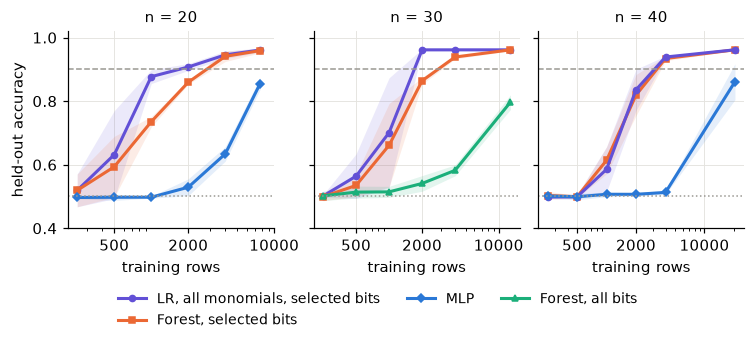

saved exp_figures/fig_learning_curves.pdf


*Mean over the folds used (shaded: one standard deviation). Dashed: 0.9 target, dotted: chance.*

| n | candidate | size 1 | size 2 | size 3 | size 4 | size 5 | size 6 |
|---|---|---|---|---|---|---|---|
| 20 | LR on all monomials on selected bits | 0.519 | 0.632 | 0.877 | 0.907 | 0.946 | 0.961 |
| 20 | random forest on selected bits | 0.519 | 0.594 | 0.735 | 0.860 | 0.941 | 0.959 |
| 20 | MLP | 0.497 | 0.498 | 0.498 | 0.529 | 0.634 | 0.855 |
| 30 | LR on all monomials on selected bits | 0.501 | 0.564 | 0.701 | 0.961 | 0.961 | 0.961 |
| 30 | random forest on selected bits | 0.499 | 0.535 | 0.661 | 0.864 | 0.939 | 0.961 |
| 30 | random forest | 0.502 | 0.514 | 0.515 | 0.541 | 0.582 | 0.797 |
| 40 | random forest on selected bits | 0.503 | 0.499 | 0.614 | 0.819 | 0.934 | 0.962 |
| 40 | LR on all monomials on selected bits | 0.498 | 0.499 | 0.585 | 0.836 | 0.939 | 0.962 |
| 40 | MLP | 0.501 | 0.499 | 0.507 | 0.507 | 0.513 | 0.861 |

Sizes: [250, 500, 1000, 2000, 4000] and the full fold-train set (7680, 12800, 20480 rows for n = 20, 30, 40).

In [26]:
import matplotlib.ticker as mticker

LC_STYLE, PAL, MKS = {}, [VIOLET, ORANGE, BLUE, AQUA, MAGENTA], ["o", "s", "D", "^", "v"]
fig, axes = plt.subplots(1, 3, figsize=(6.75, 3.0), sharey=True, layout="constrained")
tab = []
for ax, n in zip(axes, NS):
    for g in LC_CANDS[n]:
        fam, cond, sub = g["key"]
        rs = sorted(LC.where(n=n, family=fam, cond=cond, sub=sub), key=lambda r: r["size"])
        S, m, s = (
            [r["size"] for r in rs],
            np.array([r["mean"] for r in rs]),
            np.array([r["sd"] for r in rs]),
        )
        lab = sname(g["key"])
        i = LC_STYLE.setdefault(lab, len(LC_STYLE))
        col, mk = PAL[i % len(PAL)], MKS[i % len(MKS)]
        ax.plot(S, m, marker=mk, ms=4, color=col, label=lab)
        ax.fill_between(S, m - s, m + s, color=col, alpha=0.12, lw=0)
        tab.append([n, kname(g["key"])] + [f"{v:.3f}" for v in m])
    ax.axhline(0.9, color=GRAY, ls="--", lw=1)
    ax.axhline(0.5, color=GRAY, ls=":", lw=1)
    ax.set_xscale("log")
    ax.set_xticks([500, 2000, 10000])
    ax.xaxis.set_major_formatter(mticker.ScalarFormatter())
    ax.xaxis.set_minor_formatter(mticker.NullFormatter())
    ax.set_title(f"n = {n}")
    ax.set_xlabel("training rows")
    ax.set_ylim(0.40, 1.02)
axes[0].set_ylabel("held-out accuracy")
hl = {}
for ax in axes:
    for h, l in zip(*ax.get_legend_handles_labels()):
        hl.setdefault(l, h)
fig.legend(list(hl.values()), list(hl.keys()), loc="outside lower center", ncol=3)
savefig(fig, "fig_learning_curves")
display(
    Markdown(
        "*Mean over the folds used (shaded: one standard deviation). Dashed: 0.9 target, dotted:"
        " chance.*"
    )
)
display(
    Markdown(
        md_table(["n", "candidate"] + [f"size {i + 1}" for i in range(len(G["LC_SIZES"]) + 1)], tab)
        + f"\n\nSizes: {G['LC_SIZES']} and the full fold-train set"
        f" ({', '.join(str(FOLD_TRAIN[n]) for n in NS)} rows for n = 20, 30, 40)."
    )
)

## 10. Locked test, controls, hidden predictions

**10.1 Locked test, once.** The section 8 pipeline is refitted on all dev rows (80 %) and scored once on the locked 20 %. The score is stored; re-running reads it back.

In [27]:
def locked_score(n):
    key = f"locked|{n}"
    if key in FIN.rows:
        return FIN.rows[key]
    fam, cond, sub = FINAL[n]["key"]
    p = FINAL[n]["best"]["params"]
    X, B, y = load(n)
    tr, te = DEV[n], _LOCKED_IDX[n]

    def job():
        t0 = time.time()
        est = make_estimator(fam, p, cond).fit(B[tr], y[tr])
        a = acc(est, B[te], y[te])
        return dict(
            mean=a,
            sd=0.0,
            secs=round(time.time() - t0, 1),
            n_test=int(len(te)),
            train=acc(est, B[tr], y[tr]),
            half=wilson_half(a, len(te)),
            cv_mean=FINAL[n]["best"]["mean"],
            cv_sd=FINAL[n]["best"]["sd"],
            bits=[int(b) for b in est.cols_] if cond != "all" else None,
            params=p,
        )

    return run(FIN, key, job, exp="FINAL", n=n, family=fam, cond=cond, sub=sub)


tab = []
for n in NS:
    r = locked_score(n)
    tab.append([
        n,
        kname(FINAL[n]["key"]),
        f"{r['cv_mean']:.3f} ± {r['cv_sd']:.3f}",
        f"{r['mean']:.3f}",
        f"[{r['mean'] - r['half']:.3f}, {r['mean'] + r['half']:.3f}]",
        f"{r['mean'] - r['cv_mean']:+.3f}",
        "yes" if r["mean"] - r["half"] >= 0.90 else "no",
    ])
display(
    Markdown(
        md_table(
            [
                "n",
                "selected pipeline",
                "CV (dev, optimistic)",
                "locked test accuracy",
                "95% Wilson interval",
                "test minus CV",
                "interval above 0.90?",
            ],
            tab,
        )
    )
)

| n | selected pipeline | CV (dev, optimistic) | locked test accuracy | 95% Wilson interval | test minus CV | interval above 0.90? |
|---|---|---|---|---|---|---|
| 20 | LR on all monomials on selected bits | 0.960 ± 0.006 | 0.958 | [0.950, 0.966] | -0.001 | yes |
| 30 | LR on all monomials on selected bits | 0.962 ± 0.002 | 0.959 | [0.952, 0.965] | -0.004 | yes |
| 40 | random forest on selected bits | 0.960 ± 0.002 | 0.959 | [0.954, 0.964] | -0.002 | yes |

**10.2 Controls.** (a) The final pipeline is run through the same CV with **shuffled training labels** (first three folds); it must score near 0.5, otherwise something leaks. (b) The paper's Figure 2 is reproduced on its own split (`random_state=42`), as a reference only.

**Shuffled-label control of the selected pipeline**

| n | pipeline | CV accuracy with shuffled training labels | within 0.03 of chance? |
|---|---|---|---|
| 20 | LR on all monomials on selected bits | 0.504 ± 0.000 | ok |
| 30 | LR on all monomials on selected bits | 0.501 ± 0.000 | ok |
| 40 | random forest on selected bits | 0.499 ± 0.012 | ok |

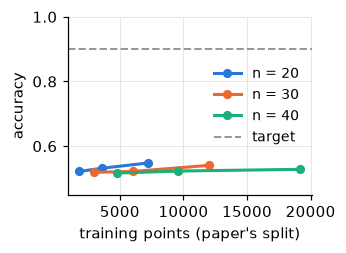

saved exp_figures/fig_paper_figure2_reproduction.pdf


In [28]:
from sklearn.model_selection import train_test_split as _tts

tab = []
for n in NS:
    fam, cond, sub = FINAL[n]["key"]
    p = FINAL[n]["best"]["params"]
    r = run(
        FIN,
        f"shuffle|{n}",
        lambda: cv_eval(
            lambda: make_estimator(fam, p, cond),
            n,
            fam=fam,
            folds=G["LC_FOLDS"],
            shuffle_labels=True,
        ),
        exp="CONTROL",
        n=n,
        family=fam,
        cond=cond,
        sub=sub,
    )
    tab.append([
        n,
        kname(FINAL[n]["key"]),
        f"{r['mean']:.3f} ± {r['sd']:.3f}",
        "ok" if abs(r["mean"] - 0.5) < 0.03 else "INVESTIGATE: possible leakage",
    ])
display(
    Markdown(
        "**Shuffled-label control of the selected pipeline**\n\n"
        + md_table(
            [
                "n",
                "pipeline",
                "CV accuracy with shuffled training labels",
                "within 0.03 of chance?",
            ],
            tab,
        )
    )
)

fig2 = {}
for n in NS:
    X, B, y = load(n)
    Xtr, Xtmp, ytr, ytmp = _tts(X, y, test_size=0.4, random_state=42)
    Xva, Xte, yva, yte = _tts(Xtmp, ytmp, test_size=0.5, random_state=42)
    fig2[n] = []
    for frac in (0.25, 0.5, 1.0):
        m = int(frac * len(ytr))
        r = run(
            FIN,
            f"paperfig2|{n}|{frac}",
            lambda: (
                lambda t0, est: dict(
                    mean=acc(est, Xte, yte), sd=0.0, secs=round(time.time() - t0, 1), size=m
                )
            )(time.time(), PaperBaseline().fit(Xtr[:m], ytr[:m])),
            exp="PAPERFIG2",
            n=n,
            family="paper",
            cond="all",
            sub=str(frac),
        )
        fig2[n].append((m, r["mean"]))
fig, ax = plt.subplots(figsize=(3.25, 2.4))
for n in NS:
    ax.plot(*zip(*fig2[n]), marker="o", color=N_COL[n], label=f"n = {n}")
ax.axhline(0.9, color=GRAY, ls="--", lw=1.3, label="target")
ax.set_xlabel("training points (paper's split)")
ax.set_ylabel("accuracy")
ax.set_ylim(0.45, 1.0)
ax.legend(frameon=False)
fig.tight_layout()
savefig(fig, "fig_paper_figure2_reproduction")

**10.3 Hidden-set predictions.** The final pipeline is refitted on **all** labelled rows and applied to the hidden inputs. The cell checks the format, class balance, that the hidden inputs look like the labelled ones, and that a second good model agrees; it writes `hiddenlabels/y_predicted_{20,30,40}.npy` at the repository root and runs the course's `check_submission.py`. `y_predicted_40_adapt.npy` is written by the LoRA notebook, not here; the check below lists it as missing until that file is in `hiddenlabels/`.

In [29]:
if WRITE_PREDICTIONS:
    os.makedirs(HIDDEN, exist_ok=True)
PRED, SELECTED = {}, {}
for n in NS:
    fam, cond, sub = FINAL[n]["key"]
    p = FINAL[n]["best"]["params"]
    X, B, y = load(n)
    Xh = np.load(f"{DATA}/hidden-kryptonite-{n}-X.npy")
    Bh = np.where(Xh > 0, 1.0, -1.0).astype(np.float32)
    est = make_estimator(fam, p, cond).fit(B, y)
    pred = est.predict(Bh).astype(np.int64)
    PRED[n] = pred
    if cond != "all":
        SELECTED[n] = [int(c) for c in est.cols_]
    assert pred.shape == (10_000,) and set(np.unique(pred)) <= {0, 1}, "wrong shape or values"
    assert 0.45 <= pred.mean() <= 0.55, f"suspicious class balance {pred.mean():.3f}"
    assert (
        np.abs(Bh.mean(0) - B.mean(0)).max() < 0.05
    ), "hidden bits do not look like the labelled bits"
    assert (
        np.mean(np.abs(Xh - Bh) < 0.5) > 0.999
    ), "hidden inputs are not clean +-1 bits plus small noise"
    msg = f"n={n}: {kname(FINAL[n]['key'])}, predicted positive rate {pred.mean():.3f}" + (
        f", bits {est.cols_}" if cond != "all" else ""
    )
    alt = next(
        (
            g
            for g in groups(n)
            if g["key"][:2] != (fam, cond) and g["key"][0] != "paper" and g["best"]["mean"] > 0.9
        ),
        None,
    )
    if alt:
        p2 = (
            make_estimator(alt["key"][0], alt["best"]["params"], alt["key"][1])
            .fit(B, y)
            .predict(Bh)
        )
        agree = float((p2 == pred).mean())
        msg += f"; agreement with {kname(alt['key'])}: {agree:.3f}" + (
            "  <-- LOW, look at this" if agree < 0.85 else ""
        )
    print(msg)
    if WRITE_PREDICTIONS:
        np.save(f"{HIDDEN}/y_predicted_{n}.npy", pred)
if WRITE_PREDICTIONS:
    for n in NS:
        a = np.load(f"{HIDDEN}/y_predicted_{n}.npy")
        assert a.shape == (10000,) and np.isin(a, [0, 1]).all()
    print("\nwritten and re-checked:", sorted(os.listdir(HIDDEN)))
    # the course's own format checker, check_submission.py, at the repository root
    try:
        sys.path.insert(0, ROOT)
        import check_submission as CS

        for name in CS.FILES:
            pr = CS.problems_with(os.path.join(HIDDEN, name))
            print(f"{'OK  ' if not pr else 'FAIL'}  {name}" + (f": {'; '.join(pr)}" if pr else ""))
    except ImportError:
        print("check_submission.py not found at the repository root; run it from there instead")

n=20: LR on all monomials on selected bits, predicted positive rate 0.499, bits [0, 1, 2, 4, 5, 7, 9, 10, 12, 15]; agreement with random forest on selected bits: 1.000
n=30: LR on all monomials on selected bits, predicted positive rate 0.501, bits [2, 5, 10, 11, 14, 17, 19, 20, 26, 28]; agreement with random forest on selected bits: 1.000
n=40: random forest on selected bits, predicted positive rate 0.504, bits [6, 7, 12, 15, 21, 24, 25, 30, 36, 39]; agreement with LR on all monomials on selected bits: 1.000

written and re-checked: ['y_predicted_20.npy', 'y_predicted_30.npy', 'y_predicted_40.npy', 'y_predicted_40_adapt.npy']
OK    y_predicted_20.npy
OK    y_predicted_30.npy
OK    y_predicted_40.npy
OK    y_predicted_40_adapt.npy


**10.4 Export and compute log.**

In [30]:
cols = ["exp", "n", "family", "cond", "sub", "size", "mean", "sd", "train", "secs", "params"]
with open(f"{OUT}/all_results.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(cols)
    for st in (CV, LC, FIN):
        for r in st.rows.values():
            w.writerow([json.dumps(r.get(c)) if c == "params" else r.get(c, "") for c in cols])
with open(f"{OUT}/cv_folds.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["n", "family", "cond", "sub", "params"] + [f"fold{i}" for i in range(K)])
    for r in CV.rows.values():
        w.writerow([r["n"], r["family"], r["cond"], r["sub"], json.dumps(r["params"])] + r["folds"])
log = {}
for st in (CV, LC, NUL, FIN):
    for r in st.rows.values():
        log[r["exp"]] = log.get(r["exp"], 0.0) + r.get("secs", 0.0)
display(
    Markdown(
        "**Compute time recorded per experiment (minutes, sum of per-fit timings; wall-clock is"
        " about 4% more)**\n\n"
        + md_table(
            ["experiment", "minutes"],
            [[k, f"{v / 60:.1f}"] for k, v in log.items()]
            + [["total", f"{sum(log.values()) / 60:.1f}"]],
        )
    )
)
# ---- configuration record: everything needed to repeat this run, next to the results
import inspect

CONFIG = dict(
    seed=SEED,
    cv_folds=K,
    n_values=list(NS),
    quick=QUICK,
    grid_hash=GRID_HASH,
    grid=G,
    flags=dict(RUN_KRYPTONET_SIZED=RUN_KRYPTONET_SIZED, WRITE_PREDICTIONS=WRITE_PREDICTIONS),
    selector=dict(
        z_floor=Z_FLOOR,
        **{
            k: v.default
            for k, v in inspect.signature(choose_bits).parameters.items()
            if v.default is not inspect.Parameter.empty
        },
    ),
    seeds_used=(
        "SEED for the locked split, the folds, every model and the inner CV; SEED+fold for"
        " training-subset draws; 1000+fold for shuffled labels; fixed small integers for the"
        " unit-test and synthetic data of section 5; random_state=42 only for the paper's own split"
        " in the Figure 2 reproduction"
    ),
    final={
        str(n): dict(
            pipeline=kname(FINAL[n]["key"]),
            key=list(FINAL[n]["key"]),
            params=FINAL[n]["best"]["params"],
            cv_mean=FINAL[n]["best"]["mean"],
            cv_sd=FINAL[n]["best"]["sd"],
            locked_accuracy=FIN.rows.get(f"locked|{n}", {}).get("mean"),
            selected_bits_fit_on_dev=FIN.rows.get(f"locked|{n}", {}).get("bits"),
            selected_bits_final_fit_on_all_labelled=SELECTED.get(n),
        )
        for n in NS
    },
)
json.dump(CONFIG, open(f"{OUT}/config.json", "w"), indent=1, default=str)
with open(f"{OUT}/sessions.jsonl", "a") as f:
    f.write(
        json.dumps(
            dict(
                event="finished",
                finished_utc=datetime.datetime.now(datetime.timezone.utc).isoformat(
                    timespec="seconds"
                ),
                recorded_fit_minutes=round(sum(log.values()) / 60, 1),
            )
        )
        + "\n"
    )
print("files in", OUT, ":", sorted(os.listdir(OUT)))
print("figures in", FIG, ":", sorted(f for f in os.listdir(FIG) if f.endswith(".pdf")))

**Compute time recorded per experiment (minutes, sum of per-fit timings; wall-clock is about 4% more)**

| experiment | minutes |
|---|---|
| BASE | 3.3 |
| LR | 9.2 |
| KPOLY | 7.4 |
| TREE | 3.1 |
| KM | 1.7 |
| MLP | 42.0 |
| SEL | 1.7 |
| SELPOLY | 3.1 |
| KPOLYC | 1.7 |
| LC | 3.2 |
| NULL | 1.0 |
| FINAL | 0.1 |
| CONTROL | 0.2 |
| PAPERFIG2 | 1.1 |
| total | 78.9 |

files in exp_results : ['.ipynb_checkpoints', 'all_results.csv', 'config.json', 'cv_folds.csv', 'cv_results.jsonl', 'environment.json', 'final.jsonl', 'learning_curves.jsonl', 'scan_cache.json', 'selector_null.jsonl', 'sessions.jsonl', 'splits.npz']
figures in exp_figures : ['fig_cv_overview.pdf', 'fig_generic.pdf', 'fig_kernel_degree.pdf', 'fig_learning_curves.pdf', 'fig_lr_degree.pdf', 'fig_paper_figure2_reproduction.pdf', 'fig_selected_bits.pdf']


## 11. Summary

One row per n, all read from the stores above.

In [31]:
rows = []
for n in NS:
    base = CV.where(n=n, family="paper")[0]
    raw = max(
        (g for g in groups(n) if g["key"][1] == "all" and g["key"][0] != "paper"),
        key=lambda g: g["best"]["mean"],
    )
    kp = CV.where(n=n, family="kpoly", sub=f"deg{n}")[0]
    big = [r for r in CV.where(n=n, family="mlp") if len(r["folds"]) == 1]
    sp = [g for g in groups(n) if g["key"] == ("lrfull", "sel", "lrfull")][0]["best"]
    rows.append([
        n,
        f"{base['mean']:.3f}",
        f"{raw['best']['mean']:.3f} ({SHORT[raw['key'][0]]})",
        f"{kp['train']:.2f} / {kp['mean']:.3f}",
        f"{big[0]['mean']:.3f}" if big else "",
        f"{sel_best(n)['mean']:.3f}",
        f"{sp['mean']:.3f}",
        f"{locked_score(n)['mean']:.3f}",
    ])
display(
    Markdown(
        md_table(
            [
                "n",
                "paper baseline (CV)",
                "best model on all bits (CV)",
                "kernel LR, degree n (train / CV)",
                "MLP 4x512 (fold 0 only)",
                "selector + forest (CV)",
                "selector + all-monomial LR (CV)",
                "locked test, chosen pipeline",
            ],
            rows,
        )
    )
)

| n | paper baseline (CV) | best model on all bits (CV) | kernel LR, degree n (train / CV) | MLP 4x512 (fold 0 only) | selector + forest (CV) | selector + all-monomial LR (CV) | locked test, chosen pipeline |
|---|---|---|---|---|---|---|---|
| 20 | 0.544 | 0.851 (MLP) | 1.00 / 0.595 | 0.932 | 0.958 | 0.960 | 0.958 |
| 30 | 0.532 | 0.784 (Forest) | 1.00 / 0.531 | 0.947 | 0.962 | 0.962 | 0.959 |
| 40 | 0.531 | 0.864 (MLP) | 1.00 / 0.502 | 0.944 | 0.960 | 0.960 | 0.959 |

**What the run shows** (figures from the table above and sections 7–10)

- **No generic model on all bits reaches 0.9 in five-fold CV.** The paper's quadratic baseline scores about 0.53–0.54. The best on all bits is the 2×128 MLP at n = 20 and 40 (about 0.85–0.86) and the forest at n = 30 (about 0.78); logistic regression up to degree 4, single trees, boosting and K-means are lower. The 4×512 MLP below is the one exception, on a single fold.
- **Degree 20+ does not rescue the paper's polynomial.** Its kernel at degree ≥ n fits the training rows (train ≈ 1.00) but scores 0.50–0.60 on held-out rows, and varying `C` over 0.1–1000 (fold 0) does not change that. The kernel table shows why: for two typical rows the kernel value is about 1e-6 (n = 20) down to 1e-12 (n = 40), against 1 for a row with itself. The Gram matrix is almost the identity, so the fit memorises the training rows and predicts close to a constant elsewhere (0.502 at n = 40).
- **The selector is what matters.** It picks the same 10 bits in every fold. A forest and a logistic regression on all monomials of those bits both reach about 0.96 in CV and on the locked test, with train ≈ CV ≈ test; they cannot be told apart (paired intervals contain 0) and their hidden predictions agree. Once the bits are chosen, the learner does not matter for the final accuracy. The polynomial needs fewer rows than the forest at n = 20 and 30 (section 9, three folds, no paired test), and the two are about equal at n = 40.
- **A 4×512 MLP on all bits** reaches 0.93–0.95 on fold 0 without any selector. That is one fold: it needs all five before it is compared.
- **The remaining ≈4 % is not explained.** Other bits as linear terms do not remove it, and the errors are only weakly predictable from them (section 7), so it is not shown to be pure label noise, but nothing here extracts it. Accuracy well above 0.96 on the locked test would call for an explanation, not a celebration.
- **Limits.** The selector is a heuristic without a family-wise guarantee, and a parity of six or more bits would be invisible to it. The locked test is one split. `y_predicted_40_adapt.npy` comes from the LoRA notebook.